Y  = simulator-generated observed choice (synthetic policy + decision noise); the models are trained on Y.
R* = synthetic reference choice (noiseless choice of the same policy). Neither is real controller behaviour.
Self-test passed: the exact filtered ceiling (subset DP) agrees with brute force over all 8! rankings.
Freeze fingerprint: 80305e8737e47afa (settings + code)
FINAL run: seeds 100-119 x 7 worlds; per seed 100 conflicts x 4 contexts = 400 scenarios x 12 simulated controllers = 4800 decisions. Main world W3. max_features = 16.
FINAL run on fresh seeds, after the freeze. CIs and p-values measure the Monte-Carlo error of the simulation,
not inference about real controllers.

Re-checking TARGETS and IDENTITIES on the development seeds 0-9 first ...
All hold. Freeze fingerprint 80305e8737e47afa (settings + code): it must match the one written down at the freeze.

=== 1. DESIGN: the vectors, the seven worlds, the fully crossed matrix ===
Controller-style vector S (simulated tendenc

,decision rule,uses style S,uses context C,style intensity scaled by context (iota),controller-specific density reaction (rho)
W0: X only,additive,no (average style S-bar),"no (5 NM everywhere, no traffic, no LOA)",no,no
W1: X + S,additive,yes,"no (5 NM everywhere, no traffic, no LOA)",no,no
W2: X + C,additive,no (average style S-bar),yes,no,no
"W3: X + S + C, additive utility [MAIN]",additive,yes,yes,no,no
W4a: W3 + style intensity scaled by context (iota),additive,yes,yes,yes,no
W4b: W3 + controller-specific density reaction (w_rho): interaction world,additive,yes,yes,no,yes
"W5: X + S + C, non-compensatory (lexicographic)",lexicographic,yes,yes,no,no


Design check: {'cells_per_controller': 4, 'controllers_per_cell': 12, 'conflicts_per_cell': 100, 'max_style_gap_between_cells': 0.0, 'total_decisions': 4800, 'scenarios': 400}


,En-route/low,En-route/high,TMA/low,TMA/high
Controller 0 (conservative),100,100,100,100
Controller 1 (moderate),100,100,100,100
Controller 2 (assertive),100,100,100,100
Controller 3 (conservative),100,100,100,100
Controller 4 (moderate),100,100,100,100
Controller 5 (assertive),100,100,100,100
Controller 6 (conservative),100,100,100,100
Controller 7 (moderate),100,100,100,100
Controller 8 (assertive),100,100,100,100
Controller 9 (conservative),100,100,100,100


Style vectors of the simulated controllers (seed 100; every seed draws new ones):


,ctrl,archetype,m,t,r,h,a,rho
0,0,conservative,0.48,423.68,0.03,11.63,-0.20,0.06
1,1,moderate,0.21,305.02,-0.76,21.60,0.02,0.94
2,2,assertive,0.04,223.84,-1.00,29.03,0.56,0.94
3,3,conservative,0.62,462.17,0.21,10.65,-0.90,0.63
4,4,moderate,0.46,177.65,-0.07,15.40,0.12,-0.16
5,5,assertive,0.00,120.00,-0.95,25.91,0.56,-0.86
6,6,conservative,0.49,425.64,0.05,8.00,-0.34,-0.25
7,7,moderate,0.28,367.41,-0.17,17.01,0.42,-0.60
8,8,assertive,0.18,245.93,-0.34,23.71,-0.12,0.11
9,9,conservative,0.55,353.75,0.11,12.31,-0.06,0.24


... (38 outputs left out)


=== 6. HOW FIRM IS 'RECOVERY'? SAMPLE SIZE AND LEARNER ===
6a. Sample-size curve: [50, 100, 200, 400] conflicts per seed (nested subsets of one draw), worlds ['W3', 'W5'], seeds 100-119
  final_curve: 20 seed(s) loaded from results/checkpoints, 0 to run
W3: X + S + C, additive utility  [MAIN]


,M0 recovery %,M1 recovery %,M2 recovery %,M3 recovery %,M3 recovery after filter %
50 conflicts (2400 decisions),"89.6 [87.9, 91.3]","89.8 [88.8, 90.7]","88.2 [86.4, 90.1]","80.1 [78.7, 81.6]",84.9
100 conflicts (4800 decisions),"90.0 [88.7, 91.4]","91.0 [90.1, 91.8]","91.1 [90.1, 92.2]","83.7 [82.6, 84.7]",87.3
200 conflicts (9600 decisions),"91.5 [90.4, 92.6]","92.0 [91.4, 92.6]","93.4 [92.7, 94.1]","86.4 [85.6, 87.3]",89.2
400 conflicts (19200 decisions),"92.5 [91.6, 93.5]","92.8 [92.3, 93.3]","94.7 [94.1, 95.4]","88.5 [87.7, 89.2]",90.6


W5: X + S + C, non-compensatory (lexicographic)


,M0 recovery %,M1 recovery %,M2 recovery %,M3 recovery %,M3 recovery after filter %
50 conflicts (2400 decisions),"84.5 [81.4, 87.6]","86.0 [84.3, 87.7]","79.8 [77.2, 82.5]","77.3 [75.6, 78.9]",82.6
100 conflicts (4800 decisions),"87.4 [85.2, 89.7]","90.0 [88.7, 91.3]","85.8 [83.8, 87.9]","83.5 [82.3, 84.7]",87.8
200 conflicts (9600 decisions),"89.1 [87.4, 90.8]","92.2 [91.6, 92.7]","89.0 [87.2, 90.8]","87.8 [87.1, 88.6]",91.4
400 conflicts (19200 decisions),"90.9 [89.6, 92.1]","93.8 [93.3, 94.2]","91.7 [90.6, 92.9]","90.7 [90.2, 91.3]",93.6


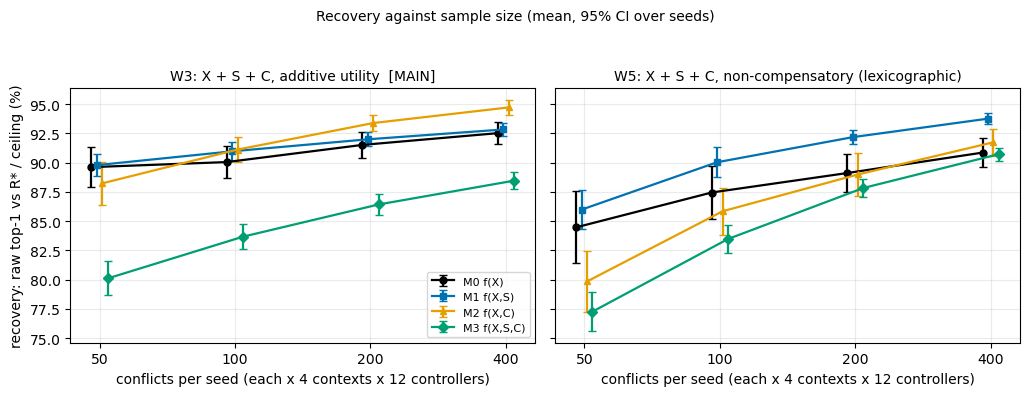

6b. Second learner (gradient-boosted trees) on the same rows and splits as the forest


,random forest: raw top-1 vs R* %,random forest: recovery %,gradient-boosted trees: raw top-1 vs R* %,gradient-boosted trees: recovery %
M0 f(X),41.5,90.1,40.7,88.1
"M1 f(X,S)",61.8,90.9,57.3,84.3
"M2 f(X,C)",52.4,91.1,48.5,84.5
"M3 f(X,S,C)",83.7,83.7,77.8,77.8
"M3id f(X, random 6-dim controller code, C)",83.5,83.5,76.1,76.1
"M3t f(X, archetype label, C)",74.6,91.2,68.6,84.1


,"H1 M3 - M3t, held-out simulated controllers, random groups, pp","H2 M3 - M2, held-out simulated controllers, whole archetype, pp","K1 M3 - M2, seen simulated controllers, pp","K2 M3 - M3id, held-out simulated controllers, random groups, pp"
random forest,"+3.0 [+0.8, +5.2] (15/20)","+18.7 [+14.1, +23.3] (19/20)","+31.3 [+29.6, +33.1] (20/20)","+25.6 [+22.2, +29.1] (20/20)"
gradient-boosted trees,"+1.2 [-1.4, +3.9] (9/20)","+18.5 [+14.8, +22.1] (20/20)","+29.3 [+26.0, +32.6] (20/20)","+22.2 [+19.3, +25.1] (20/20)"



=== 7. PREFERENCE LEVELS and the rule baselines, main world W3 (mean over 20 seeds) ===


,match R* %,P(sim. controller picks it) %
Y simulator-generated observed choice,76.9,68.0
Rule: least deviation among safe candidates (not learned),34.5,33.4
"Rule-pop: the policy with the average style S-bar (not learned, not personalised)",51.3,48.5
"M0 f(X), model alone",41.5,40.1
"M1 f(X,S), model alone",61.8,54.4
"M2 f(X,C), model alone",52.4,49.4
"M3 f(X,S,C), model alone",83.7,70.2
"M3p f(X, S and C shuffled across rows): placebo of M3, model alone",39.1,37.8
"M3pg f(X, S of another controller, C of another scenario): group placebo, model alone",60.3,53.2
"M3id f(X, random 6-dim controller code, C), model alone",83.5,70.2


R* itself matches R* by definition; the simulated controller picks it with probability 76.9%.
Rule-pop knows the policy exactly but treats every controller as the average one (style S-bar). The best any
non-personalised recommender can do is M2's ceiling, which can be higher than Rule-pop.


... (47 outputs left out)

w_rho   (W4b, seen controllers)


gain                              M1 - M0                      M2 - M0  \
param value                                                              
w_rho 0.0    +18.7 [+14.0, +23.3] / +20.9  +13.1 [+8.7, +17.4] / +14.0   
      0.5    +18.4 [+13.4, +23.4] / +20.9  +13.7 [+8.5, +18.9] / +13.7   
      1.0    +17.9 [+13.2, +22.6] / +20.2  +13.2 [+6.7, +19.7] / +13.2   
      2.0    +15.1 [+11.4, +18.8] / +18.0  +12.2 [+5.6, +18.7] / +12.6   
      3.0     +12.9 [+9.1, +16.7] / +16.0  +10.7 [+5.6, +15.9] / +11.6   

gain                              M3 - M0                       M3 - M1  \
param value                                                               
w_rho 0.0    +41.6 [+38.9, +44.3] / +53.7  +22.9 [+19.7, +26.1] / +32.8   
      0.5    +41.5 [+36.8, +46.1] / +53.7  +23.1 [+19.2, +26.9] / +32.9   
      1.0    +41.1 [+36.3, +45.9] / +53.8  +23.2 [+18.1, +28.4] / +33.6   
      2.0    +41.1 [+37.1, +45.1] / +54.8  +26.0 [+21.5, +30.5] / +36.8   
      3.0    +41.8 [+38.2, +45.4] / +56.5  +28.9 [+24.6, +33.2] / +40.5   

gain                              M3 - M2                      M3 - M3t  \
param value                                                               
w_rho 0.0    +28.5 [+23.3, +33.8] / +39.8   +10.7 [+4.4, +17.0] / +20.4   
      0.5    +27.7 [+21.5, +33.9] / +40.0   +11.3 [+6.1, +16.4] / +21.8   
      1.0    +27.9 [+21.4, +34.5] / +40.6   +12.8 [+5.9, +19.8] / +23.6   
      2.0    +28.9 [+22.1, +35.8] / +42.2   +16.4 [+9.4, +23.4] / +27.0   
      3.0    +31.1 [+25.4, +36.7] / +44.9  +19.0 [+13.2, +24.8] / +30.4   

gain         style dispersion  
param value                    
w_rho 0.0               0.249  
      0.5               0.249  
      1.0               0.249  
      2.0               0.249  
      3.0               0.249

iota   (W4a, seen controllers)


gain                              M1 - M0                       M2 - M0  \
param value                                                               
iota  0.0    +18.7 [+14.0, +23.3] / +20.9   +13.1 [+8.7, +17.4] / +14.0   
      0.5    +18.4 [+14.0, +22.8] / +20.4  +14.3 [+10.7, +17.9] / +14.5   
      1.0    +15.8 [+11.1, +20.5] / +17.9  +14.8 [+11.8, +17.7] / +15.7   
      1.5    +13.8 [+10.4, +17.3] / +15.5  +17.0 [+11.5, +22.4] / +17.7   
      2.0     +13.8 [+9.6, +18.0] / +16.1   +14.3 [+9.7, +18.8] / +15.7   

gain                              M3 - M0                       M3 - M1  \
param value                                                               
iota  0.0    +41.6 [+38.9, +44.3] / +53.7  +22.9 [+19.7, +26.1] / +32.8   
      0.5    +41.1 [+38.0, +44.1] / +54.0  +22.7 [+19.1, +26.2] / +33.6   
      1.0    +37.2 [+34.2, +40.2] / +51.1  +21.4 [+18.4, +24.4] / +33.2   
      1.5    +35.3 [+32.9, +37.7] / +47.6  +21.5 [+17.4, +25.6] / +32.1   
      2.0    +32.5 [+30.3, +34.6] / +45.5  +18.7 [+15.1, +22.3] / +29.4   

gain                              M3 - M2                     M3 - M3t  \
param value                                                              
iota  0.0    +28.5 [+23.3, +33.8] / +39.8  +10.7 [+4.4, +17.0] / +20.4   
      0.5    +26.8 [+22.3, +31.3] / +39.5  +11.1 [+6.4, +15.8] / +21.7   
      1.0    +22.4 [+16.8, +28.0] / +35.4   +9.5 [+3.6, +15.5] / +20.4   
      1.5    +18.3 [+12.7, +24.0] / +29.9   +7.7 [+1.2, +14.2] / +17.1   
      2.0    +18.2 [+12.4, +24.0] / +29.8   +7.9 [+0.4, +15.5] / +17.0   

gain         style dispersion  
param value                    
iota  0.0               0.241  
      0.5               0.241  
      1.0               0.241  
      1.5               0.241  
      2.0               0.241

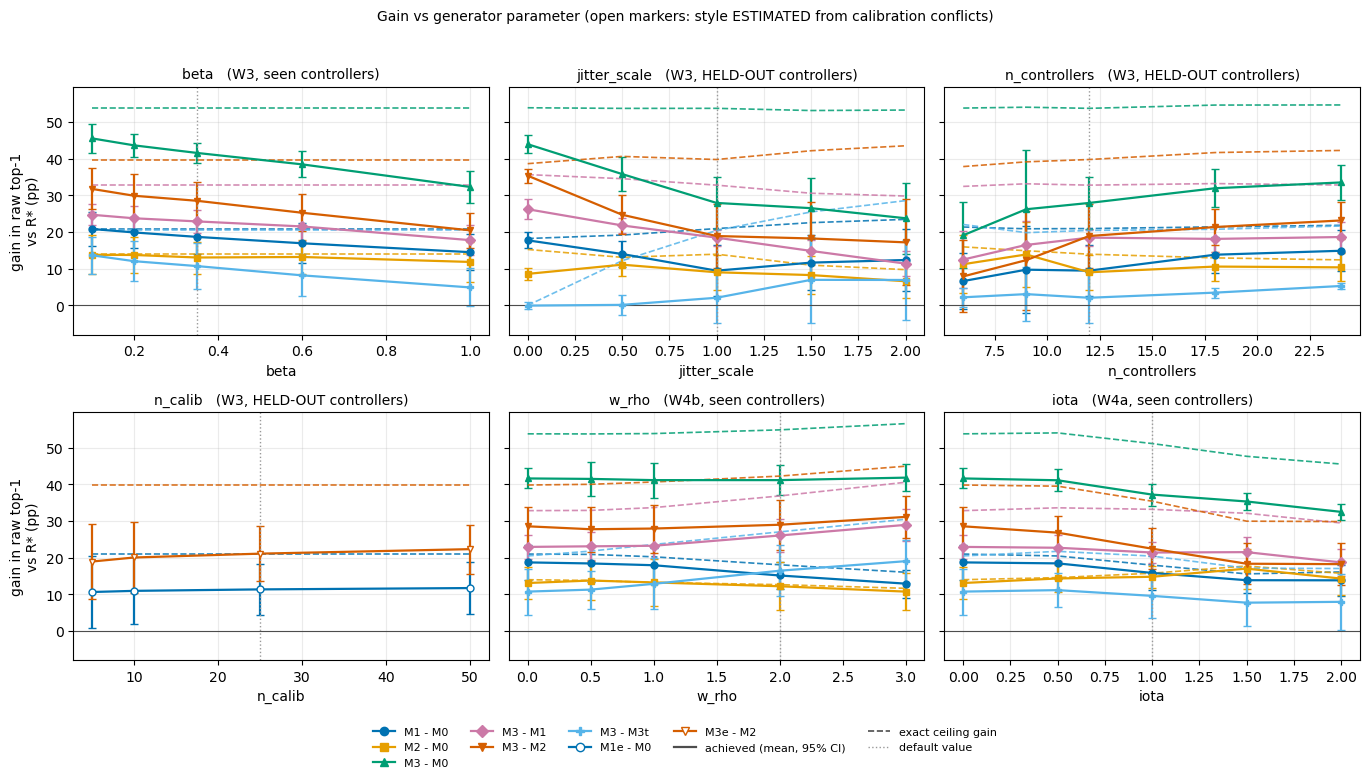


XAI: not part of this prototype. A model-faithful explanation layer, with a fidelity metric, is future work.
Tables written to results: metrics_long, choice_distribution_long, manipulation_checks, acceptance, style_profiles, rule_binding, sample_size_curve, sweeps_long, sweep_gains

Done in 0.3 min.


Exception ignored in: <function ResourceTracker.__del__ at 0x102f29bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


In [3]:

#   The protocol has six steps. MODE picks what runs:
#     step 1     MODE = "calibrate"  model-free quantities of the generator on the DEVELOPMENT seeds, checked against
#                                    TARGETS and IDENTITIES written down BEFORE the run (about a minute; no model is
#                                    trained, so the generator cannot be tuned toward a result). Prints the freeze
#                                    fingerprint.
#     step 2     MODE = "tune"       max_features of the forest on the development seeds.
#                MODE = "quick"      checks that all the code runs (development seeds, small sizes, about 10 min).
#     step 3     FREEZE              check the FROZEN block, TARGETS and Config, and write down the fingerprint that
#                                    "calibrate" prints. From then on change nothing but the SETTINGS.
#     steps 4-6  MODE = "final"      the paper run on FRESH seeds, in one pass: confirmatory tests, controller
#                                    hold-outs, sample-size curve, second learner, robustness, sweeps (about 4 h on
#                                    2 cores, e.g. Colab; about 1.3 h on 8 cores). It first re-checks every TARGET and
#                                    IDENTITY on the development seeds and refuses to start if one fails. Each seed is
#                                    saved to RESULTS_DIR as soon as it is done: after an interruption, run it again
#                                    and it resumes (same code and settings only). On Colab, mount Google Drive and
#                                    point RESULTS_DIR there, or a recycled runtime loses the checkpoints.
#   Anything added after the freeze is exploratory and is reported as such.
#
# WHAT IS SIMULATED (use these words in the paper)
#   The controllers are SIMULATED decision policies (one style vector each), not measured people. "Controller" below
#   always means a simulated controller policy; "held-out" controllers are simulated controller policies that are not in
#   the training data.
#   Y  = simulator-generated observed choice: the synthetic policy's pick WITH decision noise. Models learn from Y only.
#   R* = synthetic reference choice: the NOISELESS choice of the same policy (exists only in simulation).
#   Neither Y nor R* is real controller behaviour.
#
# STATISTICS (frozen at step 3)
#   Primary metric: raw top-1 vs R*, the share of decisions in which the recommender's own first choice, BEFORE the
#   safety filter, equals R*. Two confirmatory hypotheses on the final seeds (one-sided paired t-tests against a minimum
#   effect, Holm over both). Both are about controllers the model has NEVER seen, because on seen controllers any
#   consistent controller code personalises as well as the style vector:
#     H1  M3 - M3t   held-out controllers of known types (stratified random groups): the style vector adds to a model
#                    that already knows each controller's TYPE (the archetype label) and the context.
#     H2  M3 - M2    a whole archetype held out: the style vector lets a context-aware model serve controllers of a type
#                    it has never seen.
#   Two checks (v6's confirmatory pair) show that the generator's information is learnable. They cannot fail unless the
#   code is broken, so they are reported, not claimed: K1 M3 - M2 on seen controllers; K2 M3 - M3id on held-out
#   controllers (a random controller code instead of the style vector), minimum effect 5 pp.
#   All other contrasts are exploratory (one Holm-adjusted family) or descriptive. CIs and p-values measure the
#   MONTE-CARLO error of the simulation, not inference about real controllers.
#
# DESIGN
#   Central ablation: M0 = f(X), M1 = f(X,S), M2 = f(X,C), M3 = f(X,S,C). One learner, same rows, same folds, the same
#   number of features tried per split (max_features). Type-label arms M1t = f(X, archetype) and M3t = f(X, archetype, C)
#   measure what a three-level type label alone gives. Width-matched placebos M1p, M2p, M3p, M2sp shuffle S and/or C;
#   they are judged by their contrasts with the real arms (no ceiling or recovery is reported for them). M1e, M3e use
#   the style profile S-hat ESTIMATED from separate calibration conflicts, for the style variables whose effect on the
#   choices can be measured (r, h, a, rho); m and t are left out, because they barely move the choices (section 2).
#   Seven worlds label the same scenarios (additive worlds: same beta parameter, different resulting agreement levels;
#   see TARGETS):
#     W0 X | W1 X+S | W2 X+C        controls: the policy ignores S and/or C
#     W3 X+S+C                      MAIN world. Its utility is a sum of parts; its CHOICE is not additive (argmax)
#     W4a                           W3 + style intensity scaled by context, the same way for everyone
#     W4b                           W3 + each controller reacts to traffic density in its own direction: the interaction world
#     W5 X+S+C, non-compensatory    lexicographic policy: no criterion can make up for an earlier one
#   HEADLINE: recovery = achieved / analytic ceiling of the same information (raw: best single candidate per group;
#   filtered: best single ranking per group, exact by subset DP). Its sensitivity to sample size and learner is part
#   of the frozen run. Baselines: a least-deviation rule; Rule-pop (the policy itself with the average style S-bar).
#
# v7 CHANGES (pre-freeze review of v6). R*, P and Y are unchanged in every world.
#   - Type-label arms M1t, M3t with exact ceilings. The confirmatory pair is now H1, H2; v6's C1, C2 are checks K1, K2.
#   - TARGETS: the exact zeros moved to IDENTITIES (asserted). The within-type target was a constant; it is replaced by
#     the type-label share of the M3 - M2 ceiling gain. W5 Y = R* (fixed at 100 (1 - eps_lex) = 75%) and R1 binding
#     (kept at 0 in v6 by a penalty that duplicated R1) are reported, not targeted. W4b's interaction target is unchanged.
#   - The policy's penalties for candidates that lose separation (A_unresolved) or create a secondary conflict
#     (B_secondary) are removed: rules R1 / R1b already exclude those candidates, so the penalties never changed a choice
#     and only hid the two rules in the binding table.
#   - W4a is no longer called an interaction world. At iota = 1 it has LESS interaction than W3, and no iota below 2.5
#     gives clearly more; from 2.5 up the preferred TMA turn h (1 - 0.4 iota) is zero or negative, so iota < 2.5 is
#     asserted. W4b is the interaction world.
#   - M2sp = f(X, C, S shuffled): the width-matched comparator of K1. Interaction share also over all 8 candidates.
#   - Per-seed checkpoints with resume, a freeze fingerprint, and the final run re-checks the targets before it starts.
#   - The jitter_scale sweep is scored on held-out controllers and draws M3 - M3t: style beyond the type label vs jitter.
#
# v7.1 CHANGES (second review). R*, P, Y, every ceiling and every arm except M1e / M3e are unchanged.
#   - "synergy" is now the "ablation interaction contrast" (M3 - M1 - M2 + M0): a property of the predictors' accuracy,
#     not evidence of a style x context interaction in the decisions (its ceiling is about 20 pp in W3, which has no
#     such term, and about 25 pp in W4b, which has one).
#   - S-hat no longer has m or t slots. The old slots were the achieved margin and the decisiveness of the chosen
#     candidates; within an archetype they track r and h, not m or t, and setting m or t to the population mean changes
#     only a few % of W3's reference choices. New table: how much each style variable moves the reference choices.
#   - Held-out (not "new") simulated controllers everywhere; no ceiling or recovery for the placebo arms; beta: same
#     parameter, different resulting agreement levels, said where it matters.
#
# v7.2 CHANGES: wording only (beta and W5 agreement; S-hat as an estimate from observed decision history).
#
# MAP   1 config | 2 design | 3 environment and conflict sampling | 4 rules | 5 synthetic policies and worlds
#       6 dataset | 7 models, baselines, splits | 8 safety filter | 9 metrics, ceilings, binding, calibration
#       10 one seed | 11 sweeps, sample-size curve, tuning | 12 statistics and tables | 13 appendix | 14 RUN
# =============================================================================
 
# ---- SETTINGS (not part of the freeze) --------------------------------------------------------------------
MODE = "final"                 # "calibrate" | "tune" | "quick" | "final"  (see HOW TO USE)
N_JOBS = -1                    # parallel processes (-1 = all cores)
RUN_SWEEPS = True              # sweeps are exploratory; False saves about an eighth of the final run
SAVE_CSV = False               # True: write the long result tables to RESULTS_DIR (always on in MODE "final")
RUN_APPENDIX = False           # two pictures and a safety-filter before/after example
RESULTS_DIR = "results"        # checkpoints and tables. Colab: mount Drive and use e.g. "/content/drive/MyDrive/cdr_v7"
RESUME = True                  # reuse the per-seed checkpoints of an interrupted run (same code and settings only)
 
# ---- FROZEN AT STEP 3: the analysis plan. Change nothing here after the freeze. ---------------------------
DEV_SEEDS = list(range(0, 10))        # steps 1-2 and MODE "quick" only: these seeds have been looked at
FINAL_SEEDS = list(range(100, 120))   # steps 4-6: never looked at before the freeze
SWEEP_SEEDS = list(range(200, 205))   # sweeps: never looked at before the freeze
N_CONFLICTS = 100                     # conflicts per seed in the main run (x 4 contexts x 12 controllers)
MAIN_WORLD = "W3"                     # world of the confirmatory tests (X + S + C)
PRIMARY = ("match_rstar", " raw")     # raw top-1 vs R*: the model's own first choice, before the safety filter
HOLDOUT_RANDOM = "controller hold-out (random): unseen"      # held-out simulated controllers of known types
HOLDOUT_ARCH = "controller hold-out (archetype): unseen"     # a whole archetype of simulated controllers held out
CONFIRMATORY = [                      # (id, contrast, evaluation, minimum effect in pp): one-sided, Holm over both
    ("H1", "M3 - M3t", HOLDOUT_RANDOM, 0.0),   # DECIDE before freezing. Dev seeds: +1.9 [-1.5, +5.2]: the outcome is open
    ("H2", "M3 - M2", HOLDOUT_ARCH, 5.0),      # dev seeds: +19.5 [+12.5, +26.5]
]
CHECKS = [                            # v6's confirmatory pair: built in by the generator; reported (Holm over both), not claimed
    ("K1", "M3 - M2", "cv", 0.0),          # seen controllers. Dev seeds: +30.3 [+27.2, +33.3]
    ("K2", "M3 - M3id", HOLDOUT_RANDOM, 5.0),  # dev seeds: +26.6 [+22.4, +30.8]
]
ALPHA = 0.05                          # family-wise error rate of the two confirmatory tests
SECOND_LEARNER = "hgb"                # gradient-boosted trees (HistGradientBoostingClassifier), hyperparameters in Config
CURVE_SIZES = [50, 100, 200, 400]     # sample-size curve: conflicts per seed (nested subsets), on FINAL_SEEDS
CURVE_WORLDS = ["W3", "W5"]           # worlds of the sample-size curve
SWEEP_PARAMS = ["beta", "jitter_scale", "n_controllers", "n_calib", "w_rho", "iota"]
# Learner hyperparameters live in Config (section 1): n_trees, min_leaf, max_features (fixed with MODE "tune"), hgb_*.
 
# ---- STEP 1 TARGETS: written down BEFORE running MODE "calibrate". Each is (low, high); None = open end. -------
# Model-free quantities only: they describe the generator, so tuning it to meet them cannot favour any model. A target
# is met when its mean over the development seeds is inside the range. v7 left the generator's choices as in v5/v6:
# in Methods, say the generator was CHECKED against these targets, not calibrated to them.
TARGETS = {
    # decision noise: Y must follow R* often enough to learn from, not so often that the task is trivial. The additive
    # worlds have the same beta parameter but different resulting agreement levels (dev seeds: W0 47%, W1 69%, W2 66%,
    # W3-W4b 76-77%); agreement is checked for W3, W4a and W4b only. W5's agreement is fixed by construction at
    # 100 (1 - eps_lex) = 75%. Agreement is NOT equalised across worlds, so the control worlds W0-W2 test only that no
    # gain appears where none is possible, not levels.
    "W3: expected Y = R* %": (65, 85),
    "W4a: expected Y = R* %": (65, 85),
    "W4b: expected Y = R* %": (65, 85),
    # room to adapt: the non-adaptive ceiling stays well below 100%, and each axis carries information of its own
    "W3: raw ceiling M0 %": (30, 60),
    "W3: raw ceiling M1 - M0 pp": (10, None),
    "W3: raw ceiling M2 - M0 pp": (5, None),
    "W3: raw ceiling M3 - M1 pp": (10, None),
    "W3: raw ceiling M3 - M2 pp": (10, None),
    "W5: raw ceiling M3 - M2 pp": (10, None),
    # style vs type: H1 must not be settled by construction, so neither the three-level type label nor the individual
    # style vector may carry almost all of the style gain. This share is a MODELLING choice about real controllers;
    # if you change jitter_scale or the archetypes, give a reason that does not refer to results.
    "W3: type-label share of the raw ceiling gain M3 - M2 %": (25, 75),
    # rules: the LOA rules change choices where they apply
    "W3: binding LOA (R2-R4) in TMA %": (5, 30),
    # interaction: the interaction world has clearly more interaction than W3
    "W4b - W3: interaction share of R* pp": (10, None),
}
IDENTITIES = [   # exact zeros in every seed, by construction: they test the code, not the generator
    "W0: raw ceiling M3 - M0 pp",        # the policy ignores S and C: nothing to gain
    "W1: raw ceiling M3 - M1 pp",        # the policy ignores C
    "W1: raw ceiling M2 - M0 pp",
    "W2: raw ceiling M3 - M2 pp",        # the policy ignores S
    "W2: raw ceiling M1 - M0 pp",
    "W2: raw ceiling M3t - M2 pp",       # ... so the type label is worth nothing either
]
# -----------------------------------------------------------------------------------------------------------
 
import dataclasses
import hashlib
import inspect
import itertools
import os
import pickle
import time
from dataclasses import dataclass, field
 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import log_loss
from sklearn.model_selection import GroupKFold
 
try:
    from IPython.display import display      # tables in Jupyter / Colab
except ImportError:                          # plain Python: just print
    display = print
 
 
# %% 1. CONFIG - every number of the experiment lives here
# ---- 8 candidate resolutions: heading changes in degrees (+ = right turn), or climb / descend
CANDIDATES = [("H", -30), ("H", -20), ("H", -10), ("H", 10), ("H", 20), ("H", 30), ("V", +1), ("V", -1)]
CAND_NAMES = ["H-30", "H-20", "H-10", "H+10", "H+20", "H+30", "CLIMB", "DESCEND"]
N_CAND = len(CANDIDATES)
IS_LAT = np.array([c[0] == "H" for c in CANDIDATES])
DHDG = np.array([c[1] if c[0] == "H" else 0 for c in CANDIDATES], float)   # signed heading change (deg)
VDIR = np.array([c[1] if c[0] == "V" else 0 for c in CANDIDATES], float)   # +1 climb, -1 descend
BITS = 1 << np.arange(N_CAND)                                              # candidate k <-> bit k
SUBSETS = np.arange(1 << N_CAND)                                           # every set of candidates as a bitmask
JMAX = 48                                                                  # largest number of controllers supported
 
# ---- controller-style vector S = [m, t, r, h, a, rho]  (what a simulated controller TENDS to do)
STYLE_VARS = ["m", "t", "r", "h", "a", "rho"]
STYLE_DOC = {
    "m": "preferred separation margin: wanted buffer above the minimum, as a fraction (0.25 = 25% above)",
    "t": "intervention timing: preferred lead time before CPA, seconds (large = acts early)",
    "r": "resolution type: -1 always vertical ... +1 always lateral (heading)",
    "h": "preferred heading-change magnitude, degrees",
    "a": "altitude preference: -1 prefers descend ... +1 prefers climb",
    "rho": "context reactivity: how the lateral-vs-vertical preference shifts with traffic density "
           "(-1 more vertical in dense traffic ... +1 more lateral); only world W4b uses it",
}
STYLE_BOUNDS = {"m": (0.0, 0.8), "t": (120, 480), "r": (-1, 1), "h": (8, 32), "a": (-1, 1), "rho": (-1, 1)}
# archetypes only GENERATE controllers (centre + jitter) for m, t, r, h, a; rho is drawn on its own.
# The archetype label is used for the archetype hold-out and for reporting. The only models that see it are the
# type-label arms M1t and M3t, which exist to measure what the label alone is worth.
ARCHETYPES = {
    "conservative": dict(m=0.50, t=400, r=+0.5, h=12, a=-0.3),
    "moderate":     dict(m=0.25, t=300, r=0.0, h=20, a=0.0),
    "assertive":    dict(m=0.05, t=200, r=-0.5, h=28, a=+0.4),
}
STYLE_JITTER = dict(m=0.10, t=50, r=0.30, h=3.5, a=0.30)
STYLE_MEAN = {v: float(np.mean([arch[v] for arch in ARCHETYPES.values()])) for v in STYLE_JITTER}
STYLE_MEAN["rho"] = 0.0          # the population-average style S-bar: policies without S, and Rule-pop
 
# ---- context vector C (situation; contains NO controller information)
CONTEXT_DOC = {
    "is_tma": "airspace type: 0 = en-route, 1 = TMA",
    "is_high": "traffic density level: 0 = low, 1 = high",
    "n_nb": "number of surrounding aircraft (realised)",
    "nb_nearest": "distance to the nearest surrounding aircraft (NM)",
    "bnd_dist": "distance to the sector boundary (NM)",
    "bnd_side": "side of the neighbouring sector: -1 left, +1 right",
    "secd_k": "per candidate: min distance to surrounding traffic after the manoeuvre (NM)",
}
 
# ---- worlds: which information the synthetic decision policy is allowed to use, and how it decides
WORLDS = {
    "W0": dict(label="X only", kind="additive", S=False, C=False, iota=False, rho=False),
    "W1": dict(label="X + S", kind="additive", S=True, C=False, iota=False, rho=False),
    "W2": dict(label="X + C", kind="additive", S=False, C=True, iota=False, rho=False),
    "W3": dict(label="X + S + C, additive utility", kind="additive", S=True, C=True, iota=False, rho=False),
    "W4a": dict(label="W3 + style intensity scaled by context (iota)", kind="additive", S=True, C=True, iota=True, rho=False),
    "W4b": dict(label="W3 + controller-specific density reaction (w_rho): interaction world", kind="additive", S=True,
                C=True, iota=False, rho=True),
    "W5": dict(label="X + S + C, non-compensatory (lexicographic)", kind="lexicographic", S=True, C=True, iota=False, rho=False),
}
 
 
@dataclass
class Config:
    seed: int = 0
    # ---- design (fully crossed: every controller x every context cell x every conflict)
    n_controllers: int = 12                                                   # [swept]
    n_conflicts: int = 100            # conflicts per seed; each is replayed in all 4 context cells
    n_calib: int = 25                 # calibration conflicts used to estimate style profiles               [swept]
    calib_pool: int = 50              # calibration conflicts simulated; the first n_calib are used (nested)
    accept_batch: int = 40            # conflicts drawn per batch by the rejection sampler
    airspaces: tuple = ("enroute", "tma")
    densities: tuple = ("low", "high")
    # ---- physics
    dt: float = 5.0                   # s
    response_delay: float = 15.0      # s between instruction and manoeuvre start
    climb_rate: float = 16.7          # ft/s (1000 ft/min)
    vert_step: float = 2000.0         # ft
    v_req: float = 1000.0             # ft vertical minimum
    h_req: dict = field(default_factory=lambda: {"enroute": 5.0, "tma": 3.0})   # NM horizontal minimum
    horizon_extra: float = 180.0      # s simulated after CPA
    slack_step: float = 5.0           # s, grid of instruction delays for the timing slack
    # ---- conflict sampler (identical in every context: X carries no context information)
    t_cpa: tuple = (90.0, 480.0)      # s from decision time to CPA
    d_cpa: tuple = (0.0, 2.4)         # NM predicted miss distance (< both minima: a real conflict)
    speed: tuple = (250.0, 450.0)     # kt
    fl: tuple = (80.0, 200.0)         # flight level of ownship
    dz0: tuple = (-800.0, 800.0)      # ft initial vertical offset (< v_req)
    cross: tuple = (20.0, 170.0)      # deg track crossing angle
    # ---- surrounding traffic (part of the context)
    nb_lambda: dict = field(default_factory=lambda: {"low": 2.0, "high": 12.0})
    nb_radius: float = 40.0           # NM
    nb_dz: float = 2000.0             # ft, uniform +-
    # ---- LOA / operational rules (limited, formalised)
    loa_tma_climb_max_fl: float = 160.0   # R2: in TMA, no climb when ownship is above this FL
    loa_tma_desc_min_fl: float = 100.0    # R2: in TMA, no descent when ownship is below this FL
    loa_boundary_nm: dict = field(default_factory=lambda: {"enroute": 12.0, "tma": 8.0})  # R3: no turn towards boundary if closer
    loa_tma_max_turn: float = 20.0        # R4: in TMA, turns above this need coordination -> not allowed
    # ---- additive policy, over the rule-valid candidates: U = margin + geometry + Preference(S) + ContextFit(C) - Deviation
    #      (a candidate that loses separation or creates a secondary conflict breaks R1 / R1b and is not available, so
    #      neither is also coded as a penalty)
    gamma_margin: float = 0.4
    w_m: float = 3.0       # margin shortfall
    w_t: float = 1.0       # timing urgency x decisiveness
    w_r: float = 2.0       # lateral vs vertical
    w_h: float = 1.2       # heading magnitude mismatch
    w_a: float = 0.8       # climb vs descend
    b_type: dict = field(default_factory=lambda: {"enroute": -0.1, "tma": 0.8})   # habit: lateral(+)/vertical(-)
    b_dir: dict = field(default_factory=lambda: {"enroute": 0.0, "tma": 0.5})     # habit: right turns
    kappa_dens: float = 1.2    # high density penalises big lateral manoeuvres
    w_geo: float = 0.05        # geometry tie-breaker (X, every world): all else equal, move vertically AWAY from the intruder
    w_d: float = 0.6           # deviation cost
    dev_vertical: float = 0.4  # normalised deviation of a vertical manoeuvre
    beta: float = 0.35         # decision noise of the additive policies (softmax temperature)        [swept]
    h_req_blind: float = 5.0   # W0, W1: a policy that cannot see the context uses 5 NM everywhere
    iota: float = 1.0          # W4a: style intensity scaled by context, the same way for everyone; < 2.5  [swept]
    w_rho: float = 2.0         # W4b: each controller reacts to traffic density in its own direction  [swept]
    jitter_scale: float = 1.0  # multiplies STYLE_JITTER and the spread of rho                         [swept]
    # ---- lexicographic policy (W5)
    lex_type_thr: float = 0.2  # |r| above which the controller's own type beats the sector habit
    lex_dir_thr: float = 0.1   # |a| above which the controller's climb/descend preference is used
    eps_lex: float = 0.25      # decision noise of W5: with this probability another valid candidate, at random,
    #                            so W5's expected Y = R* is 100 (1 - eps_lex) = 75% by construction
    min_viable: int = 2        # a conflict is accepted if it has >= this many rule-valid candidates in EVERY context
    # ---- learning (frozen at step 3)
    n_trees: int = 100
    min_leaf: int = 2          # minimum samples per leaf of the random forest
    max_features: int = 16     # features tried at each split, the SAME for every model and arm (fixed with MODE "tune")
    hgb_lr: float = 0.1        # second learner: gradient-boosted trees, library defaults except early stopping off
    hgb_iter: int = 200
    hgb_leaves: int = 31
    hgb_min_leaf: int = 20
    n_folds: int = 5
    n_jobs: int = 1            # cores per model (the seeds already run in parallel)
 
 
def h_req_of(cfg, is_tma):
    """Horizontal separation minimum (NM) for an array of is_tma flags."""
    return np.where(np.asarray(is_tma) > 0, cfg.h_req["tma"], cfg.h_req["enroute"])
 
 
# %% 2. DESIGN - controllers (style vectors), contexts, full-factorial matrix
def make_controllers(cfg, rng):
    """Simulated controllers: one style VECTOR S = [m,t,r,h,a,rho] each. Archetypes only seed m..a (centre + jitter);
    rho is drawn on its own stream. jitter_scale scales both spreads. Controllers are drawn one after the other, so the
    first J controllers are the same whatever n_controllers is."""
    names = list(ARCHETYPES)
    rho = np.random.default_rng([cfg.seed, 11]).uniform(-1, 1, cfg.n_controllers) * cfg.jitter_scale
    rows = []
    for j in range(cfg.n_controllers):
        arch = names[j % len(names)]
        s = {k: ARCHETYPES[arch][k] + rng.normal(0, STYLE_JITTER[k] * cfg.jitter_scale) for k in STYLE_JITTER}
        s["rho"] = rho[j]
        for k in STYLE_VARS:
            lo, hi = STYLE_BOUNDS[k]
            s[k] = float(np.clip(s[k], lo, hi))
        rows.append(dict(ctrl=j, archetype=arch, **s))
    return pd.DataFrame(rows)
 
 
def style_dispersion(ctrl, variables=tuple(STYLE_VARS)):
    """Realised spread of the controllers' styles: mean over the given style variables of SD / range of the variable."""
    return float(np.mean([ctrl[v].std(ddof=0) / (STYLE_BOUNDS[v][1] - STYLE_BOUNDS[v][0]) for v in variables]))
 
 
def make_cells(cfg):
    """Context cells = airspace type x traffic density."""
    rows = []
    for z in cfg.airspaces:
        for d in cfg.densities:
            rows.append(dict(cell=len(rows), airspace=z, density=d, is_tma=int(z == "tma"), is_high=int(d == "high"),
                             label=f"{'TMA' if z == 'tma' else 'En-route'}/{d}"))
    return pd.DataFrame(rows)
 
 
def design_matrix(cfg, ctrl, cells):
    """One row = one decision to simulate: (controller, cell, conflict)."""
    idx = pd.MultiIndex.from_product([ctrl.ctrl, cells.cell, range(cfg.n_conflicts)], names=["ctrl", "cell", "conf"])
    return idx.to_frame(index=False)
 
 
def crossing_report(design, ctrl, cells):
    """Rows = controllers, columns = contexts, entries = number of conflicts."""
    tab = design.groupby(["ctrl", "cell"]).size().unstack("cell")
    tab.columns = list(cells.label)
    tab.index = [f"Controller {c} ({a})" for c, a in zip(ctrl.ctrl, ctrl.archetype)]
    return tab
 
 
def check_design(design, ctrl, cells, cfg):
    """Hard checks: raises AssertionError if the design is not balanced / not independent."""
    tab = design.groupby(["ctrl", "cell"]).size().unstack("cell")
    assert tab.shape == (len(ctrl), len(cells)), "some controller x context cell is missing"
    assert (tab.values == cfg.n_conflicts).all(), "unequal number of conflicts per cell"
    paired = design.groupby("conf").size()
    assert (paired == len(ctrl) * len(cells)).all(), "a conflict is not replayed in every controller x context"
    ctx_names = {"is_tma", "is_high", "n_nb", "nb_nearest", "bnd_dist", "bnd_side", "secd_k"}
    assert not (set(STYLE_VARS) & ctx_names), "a variable is in both S and C"
    d = design.merge(ctrl[["ctrl"] + STYLE_VARS], on="ctrl")
    smd = max(abs(d.groupby("cell")[k].mean().max() - d.groupby("cell")[k].mean().min()) / (d[k].std() + 1e-9)
              for k in STYLE_VARS)
    assert smd < 1e-9, f"style differs between context cells (standardised gap {smd:.3g})"
    return {"cells_per_controller": tab.shape[1], "controllers_per_cell": tab.shape[0],
            "conflicts_per_cell": int(tab.values[0, 0]), "max_style_gap_between_cells": float(smd),
            "total_decisions": len(design), "scenarios": cfg.n_conflicts * len(cells)}
 
 
def describe_vectors():
    print("Controller-style vector S (simulated tendencies):")
    for k in STYLE_VARS:
        print(f"  {k}: {STYLE_DOC[k]}")
    print("Context vector C (situation, no controller information):")
    for k, v in CONTEXT_DOC.items():
        print(f"  {k}: {v}")
    print("Type label (archetype: conservative / moderate / assertive): seen only by the type-label arms M1t and M3t.")
 
 
# %% 3. ENVIRONMENT - conflicts, surrounding traffic, simulation of the candidates, conflict sampling
KT = 1.0 / 3600.0          # kt -> NM/s
DEV_T = 300.0              # s, fixed time at which lateral deviation is measured
DEV_NORM = 15.0            # NM, lateral displacement that counts as deviation = 1.0
 
 
def _dir(hdg_deg):
    h = np.deg2rad(hdg_deg)
    return np.array([np.sin(h), np.cos(h)])          # (east, north)
 
 
def make_conflicts(cfg, rng):
    """cfg.n_conflicts candidate conflicts: ownship at the origin, intruder placed so CPA happens at t_cpa with miss d_cpa."""
    rows = []
    while len(rows) < cfg.n_conflicts:
        v_o, v_i = rng.uniform(*cfg.speed), rng.uniform(*cfg.speed)
        hdg_o = rng.uniform(0, 360)
        cross = rng.uniform(*cfg.cross) * rng.choice([-1, 1])
        hdg_i = (hdg_o + cross) % 360
        T, d = rng.uniform(*cfg.t_cpa), rng.uniform(*cfg.d_cpa)
        vo, vi = v_o * KT * _dir(hdg_o), v_i * KT * _dir(hdg_i)
        vrel = vi - vo
        if np.linalg.norm(vrel) < 60 * KT:
            continue
        n_hat = np.array([-vrel[1], vrel[0]]) / np.linalg.norm(vrel) * rng.choice([-1, 1])
        p_i0 = vo * T + d * n_hat - vi * T                       # intruder position at t=0
        fl_o, dz0 = rng.uniform(*cfg.fl), rng.uniform(*cfg.dz0)
        bearing = (np.degrees(np.arctan2(p_i0[0], p_i0[1])) - hdg_o + 180) % 360 - 180
        rows.append(dict(conf=len(rows), v_o=v_o, v_i=v_i, hdg_o=hdg_o, hdg_i=hdg_i, fl_o=fl_o, dz0=dz0,
                         t_cpa=T, d_cpa=d, cross=abs(cross), cur_sep=float(np.linalg.norm(p_i0)),
                         intr_bearing=bearing, pxi=p_i0[0], pyi=p_i0[1]))
    return pd.DataFrame(rows)
 
 
def neighbours_for(cfg, c, cell, stream=0):
    """Deterministic surrounding traffic + boundary geometry for (conflict, context cell); stream separates the
    calibration conflicts from the main ones."""
    rng = np.random.default_rng([cfg.seed, 7, int(c["conf"]), int(cell["cell"])] + ([stream] if stream else []))
    lam = cfg.nb_lambda[cell["density"]]
    n = int(np.clip(rng.poisson(lam), 0 if cell["density"] == "low" else 4, 5 if cell["density"] == "low" else 14))
    r = cfg.nb_radius * np.sqrt(rng.uniform(0.02, 1, n))
    ang = rng.uniform(0, 2 * np.pi, n)
    pos = np.stack([r * np.sin(ang), r * np.cos(ang)], 1)
    hdg = rng.uniform(0, 360, n)
    vel = np.stack([rng.uniform(*cfg.speed, n) * KT * np.sin(np.deg2rad(hdg)),
                    rng.uniform(*cfg.speed, n) * KT * np.cos(np.deg2rad(hdg))], 1)
    z = c["fl_o"] * 100 + rng.uniform(-cfg.nb_dz, cfg.nb_dz, n)
    nb = dict(pos=pos, vel=vel, z=z)
    # drop neighbours already in nominal conflict with the ownship (secondary conflicts must come from the manoeuvre)
    keep = np.ones(n, bool)
    if n:
        d_nom, _ = _min_dist(cfg, c, nb, _times(cfg, c), None)
        keep = d_nom >= 1.2 * max(cfg.h_req.values())
    nb = {k: v[keep] for k, v in nb.items()}
    geo = dict(bnd_dist=float(rng.uniform(3, 60)), bnd_side=int(rng.choice([-1, 1])))
    return nb, geo
 
 
def _times(cfg, c):
    """Time grid: from now to CPA + horizon_extra (at least DEV_T so deviation is always measurable)."""
    return np.arange(0, max(c["t_cpa"] + cfg.horizon_extra, DEV_T) + cfg.dt, cfg.dt)
 
 
def _own_path(cfg, c, k, t, extra_delay=0.0):
    """Ownship (xy, z) over time t for candidate k (k=None: no action)."""
    v, d0, tau = c["v_o"] * KT, _dir(c["hdg_o"]), cfg.response_delay + extra_delay
    z0 = c["fl_o"] * 100.0
    if k is None or not IS_LAT[k] and VDIR[k] == 0:
        return v * d0[None, :] * t[:, None], np.full_like(t, z0)
    if IS_LAT[k]:
        d1 = _dir(c["hdg_o"] + DHDG[k])
        xy = v * (d0[None, :] * np.minimum(t, tau)[:, None] + d1[None, :] * np.maximum(t - tau, 0)[:, None])
        return xy, np.full_like(t, z0)
    z = z0 + VDIR[k] * np.minimum(np.maximum(t - tau, 0) * cfg.climb_rate, cfg.vert_step)
    return v * d0[None, :] * t[:, None], z
 
 
def _min_dist(cfg, c, nb, t, k, extra_delay=0.0):
    """Min horizontal distance to each neighbour during times when vertical separation < v_req."""
    own, z_o = _own_path(cfg, c, k, t, extra_delay)
    pos_t = nb["pos"][:, None, :] + nb["vel"][:, None, :] * t[None, :, None]
    dist = np.linalg.norm(own[None] - pos_t, axis=2)
    close = np.abs(z_o[None, :] - nb["z"][:, None]) < cfg.v_req
    return np.where(close, dist, np.inf).min(axis=1), own
 
 
def primary_dmin(cfg, c, k, extra_delay=0.0):
    """Min horizontal distance to the intruder while vertical separation < v_req (NM)."""
    t = _times(cfg, c)
    own, z_o = _own_path(cfg, c, k, t, extra_delay)
    intr = np.array([c["pxi"], c["pyi"]])[None, :] + (c["v_i"] * KT * _dir(c["hdg_i"]))[None, :] * t[:, None]
    dist = np.linalg.norm(own - intr, axis=1)
    z_i = c["fl_o"] * 100.0 + c["dz0"]
    close = np.abs(z_o - z_i) < cfg.v_req
    return float(dist[close].min() if close.any() else dist.min())
 
 
def candidate_outcomes(cfg, c, nb):
    """For one (conflict, context): dmin_k (primary), dev_k (deviation index), secd_k (neighbours), k = 0..7."""
    t = _times(cfg, c)
    nom, _ = _own_path(cfg, c, None, t)
    i_dev = int(DEV_T / cfg.dt)
    dmin, dev, secd = np.zeros(N_CAND), np.zeros(N_CAND), np.full(N_CAND, 99.0)
    for k in range(N_CAND):
        dmin[k] = primary_dmin(cfg, c, k)
        if IS_LAT[k]:
            own, _ = _own_path(cfg, c, k, t)
            dev[k] = np.linalg.norm(own[i_dev] - nom[i_dev]) / DEV_NORM
        else:
            dev[k] = cfg.dev_vertical
        if len(nb["z"]):
            secd[k] = min(99.0, _min_dist(cfg, c, nb, t, k)[0].min())
    return dmin, dev, secd
 
 
def slack_table(cfg, conflicts):
    """Timing slack (s) for every conflict x candidate x minimum (index 0 = en-route 5 NM, 1 = TMA 3 NM): the longest
    delay d such that the candidate resolves for EVERY delay on the grid 0, step, ..., d (0 if it does not resolve even
    without delay). No monotonicity is assumed: the whole grid up to CPA is simulated, and cases where a longer delay
    resolves again after a failure are counted."""
    out, non_monotone = np.zeros((len(conflicts), N_CAND, 2)), 0
    for _, c in conflicts.iterrows():
        delays = np.arange(0.0, c["t_cpa"] + 1e-9, cfg.slack_step)
        for k in range(N_CAND):
            d = np.array([primary_dmin(cfg, c, k, x) for x in delays])
            for i, z in enumerate(("enroute", "tma")):
                ok = d >= cfg.h_req[z]
                n_ok = len(ok) if ok.all() else int(np.argmin(ok))       # length of the run of successes from delay 0
                out[int(c["conf"]), k, i] = delays[n_ok - 1] if n_ok > 0 else 0.0
                non_monotone += int(ok[n_ok:].any())
    return out, 100 * non_monotone / (len(conflicts) * N_CAND * 2)
 
 
def build_scenarios(cfg, conflicts, cells, stream=0):
    """Scenario table = conflict x context cell, with the simulated outcome of every candidate."""
    rows = []
    for _, cell in cells.iterrows():
        for _, c in conflicts.iterrows():
            nb, geo = neighbours_for(cfg, c, cell, stream)
            dmin, dev, secd = candidate_outcomes(cfg, c, nb)
            d_nb = np.linalg.norm(nb["pos"], axis=1) if len(nb["z"]) else np.array([60.0])
            r = dict(conf=int(c["conf"]), cell=int(cell["cell"]), is_tma=int(cell["is_tma"]), is_high=int(cell["is_high"]),
                     n_nb=len(nb["z"]), nb_nearest=float(d_nb.min()), **geo)
            r.update({f"dmin_{k}": dmin[k] for k in range(N_CAND)})
            r.update({f"dev_{k}": dev[k] for k in range(N_CAND)})
            r.update({f"secd_{k}": secd[k] for k in range(N_CAND)})
            rows.append(r)
    scen = pd.DataFrame(rows)
    scen.insert(0, "scen", range(len(scen)))
    return scen.merge(conflicts, on="conf", how="left")
 
 
def sample_conflicts(cfg, rng, cells, n, stream=0):
    """Rejection sampling. Conflicts are drawn in batches and simulated in every context; a conflict is ACCEPTED when it
    has at least min_viable rule-valid candidates in ALL contexts. Then n conflicts are drawn uniformly from the accepted
    pool. Returns (conflicts, scenarios, acceptance statistics)."""
    acc_c, acc_s, drawn = [], [], 0
    solvable = np.zeros(len(cells))
    while sum(len(a) for a in acc_c) < n:
        batch = make_conflicts(dataclasses.replace(cfg, n_conflicts=cfg.accept_batch), rng)
        batch["conf"] = batch["conf"] + drawn
        sc = build_scenarios(cfg, batch, cells, stream)
        ok = sc.assign(ok=valid_mask(cfg, sc).sum(1) >= cfg.min_viable).pivot(index="conf", columns="cell", values="ok")
        solvable += ok.sum(axis=0).values
        good = ok.index[ok.all(axis=1).values]
        acc_c.append(batch[batch.conf.isin(good)])
        acc_s.append(sc[sc.conf.isin(good)])
        drawn += cfg.accept_batch
        if drawn > 100 * n:
            raise RuntimeError("conflict acceptance rate is too low: check the rules or min_viable")
    conflicts, sc = pd.concat(acc_c), pd.concat(acc_s)
    accepted = len(conflicts)
    pick = np.sort(rng.choice(conflicts.conf.values, n, replace=False))          # uniform over the accepted pool
    remap = {c: i for i, c in enumerate(pick)}
    conflicts = conflicts[conflicts.conf.isin(pick)].copy()
    conflicts["conf"] = conflicts.conf.map(remap)
    conflicts = conflicts.sort_values("conf").reset_index(drop=True)
    sc = sc[sc.conf.isin(pick)].copy()
    sc["conf"] = sc.conf.map(remap)
    sc = sc.sort_values(["cell", "conf"]).reset_index(drop=True)
    sc["scen"] = np.arange(len(sc))
    stats_ = dict(drawn=drawn, accepted=accepted, acceptance_rate=accepted / drawn)
    stats_.update({f"solvable in {lab} %": 100 * s / drawn for lab, s in zip(cells.label, solvable)})
    return conflicts, sc, stats_
 
 
# %% 4. RULES - separation minimum and LOA rules (one definition used everywhere; always judged in the REAL context)
RULES = {
    "R1":  "separation minimum: the manoeuvre must resolve the predicted conflict (horizontal minimum by airspace type)",
    "R1b": "no secondary conflict with surrounding traffic",
    "R2":  "LOA level restriction (TMA): no climb above / no descent below the agreed levels",
    "R3":  "LOA transfer condition: no turn towards the sector boundary when closer than the agreed distance",
    "R4":  "LOA coordination (TMA): turns larger than the agreed limit need coordination, so not auto-recommended",
}
 
 
def violations(cfg, sc):
    """dict rule -> bool array (n_rows, 8), True = the candidate VIOLATES the rule."""
    tma = sc.is_tma.values[:, None].astype(bool)
    H = h_req_of(cfg, sc.is_tma.values)[:, None]
    dmin = sc[[f"dmin_{k}" for k in range(N_CAND)]].values
    secd = sc[[f"secd_{k}" for k in range(N_CAND)]].values
    fl = sc.fl_o.values[:, None]
    climb, desc = VDIR[None, :] > 0, VDIR[None, :] < 0
    bnd = np.where(tma, cfg.loa_boundary_nm["tma"], cfg.loa_boundary_nm["enroute"])
    toward = (np.sign(DHDG)[None, :] == sc.bnd_side.values[:, None]) & IS_LAT[None, :]
    return {
        "R1": dmin < H,
        "R1b": secd < H,
        "R2": tma & ((climb & (fl > cfg.loa_tma_climb_max_fl)) | (desc & (fl < cfg.loa_tma_desc_min_fl))),
        "R3": toward & (sc.bnd_dist.values[:, None] < bnd),
        "R4": tma & (np.abs(DHDG)[None, :] > cfg.loa_tma_max_turn),
    }
 
 
def valid_mask(cfg, sc, rules=None):
    """True where a candidate violates NO rule (optionally only the given rules)."""
    v = violations(cfg, sc)
    bad = np.zeros((len(sc), N_CAND), bool)
    for r in (v if rules is None else rules):
        bad |= v[r]
    return ~bad
 
 
# %% 5. SYNTHETIC DECISION POLICIES and the seven worlds
LAT = IS_LAT.astype(float)
MAG = np.abs(DHDG)
DECISIVE = np.where(IS_LAT, MAG / 30.0, 0.8)       # how "decisive" a candidate is (vertical counted as 0.8)
 
 
def _style(ctrl, use_s):
    """(1, J) array per style variable: the controllers' own style, or the population-average style S-bar."""
    J = len(ctrl)
    return ({v: ctrl[v].values[None, :] for v in STYLE_VARS} if use_s
            else {v: np.full((1, J), STYLE_MEAN[v]) for v in STYLE_VARS})
 
 
def policy_utility(cfg, sc, ctrl, world, pop=False):
    """Additive policy. Utility U[scenario, controller, candidate], its named parts, and the margin each controller
    wants (m_eff). Without S every controller has the population-average style (pop=True forces it: Rule-pop); without
    C the policy sees no airspace (5 NM everywhere), no density, no surrounding traffic and no LOA habits. iota: style
    intensity scaled by context (same for everyone). rho: each controller's lateral-vs-vertical preference reacts to
    density in its own direction. The policy chooses among the candidates of policy_valid only, so a candidate that loses
    separation or creates a secondary conflict (rules R1, R1b) never competes: U carries no penalty for either."""
    W = WORLDS[world]
    n, J = len(sc), len(ctrl)
    dmin = sc[[f"dmin_{k}" for k in range(N_CAND)]].values
    dev = sc[[f"dev_{k}" for k in range(N_CAND)]].values
    if W["C"]:
        H = h_req_of(cfg, sc.is_tma.values)[:, None]
        hi, tm = sc.is_high.values[:, None].astype(float), sc.is_tma.values[:, None].astype(float)
    else:
        H = np.full((n, 1), cfg.h_req_blind)
        hi, tm = np.zeros((n, 1)), np.zeros((n, 1))
    mu = (dmin - H) / H                                                     # fractional margin above the minimum
 
    margin = cfg.gamma_margin * np.clip(mu, 0, 1)                           # (n,K) bonus for margin above the minimum
    geo = cfg.w_geo * -np.sign(sc.dz0.values)[:, None] * VDIR[None, :]      # (n,K) intruder above -> descend (breaks ties)
 
    st = _style(ctrl, W["S"] and not pop)
    io = cfg.iota if W["iota"] else 0.0
    assert 1 - 0.4 * io > 0, "iota >= 2.5 makes the preferred TMA turn size h (1 - 0.4 iota) zero or negative"
    m = st["m"] * (1 + io * 0.8 * hi)                                      # (n,J) denser traffic -> more margin wanted
    t = st["t"] * (1 + io * 0.5 * hi)                                      # denser traffic -> acts earlier
    h = st["h"] * (1 - io * 0.4 * tm)                                      # TMA -> smaller turns preferred
    r, a = st["r"][:, :, None], st["a"][:, :, None]
    u_time = np.clip((t - sc.t_cpa.values[:, None]) / 300.0, -1, 1)        # >0: the conflict is later than I like
    pref = (-cfg.w_m * np.maximum(0, m[:, :, None] - np.clip(mu, 0, None)[:, None, :])
            + cfg.w_t * u_time[:, :, None] * (DECISIVE[None, None, :] - 0.5)
            + cfg.w_r * r * (LAT[None, None, :] - 0.5)
            - cfg.w_h * ((MAG[None, None, :] - h[:, :, None]) / 10.0) ** 2 * LAT[None, None, :]
            + cfg.w_a * a * VDIR[None, None, :])
    if W["rho"]:   # each controller reacts to dense traffic in its OWN direction: a genuine style x context interaction
        pref = pref + cfg.w_rho * st["rho"][:, :, None] * (hi - 0.5)[:, :, None] * (2 * LAT[None, None, :] - 1)
 
    if W["C"]:
        z = np.where(sc.is_tma.values > 0, "tma", "enroute")
        b_type = np.array([cfg.b_type[v] for v in z])[:, None]
        b_dir = np.array([cfg.b_dir[v] for v in z])[:, None]
        ctx = (b_type * (LAT[None, :] - 0.5) + b_dir * np.sign(DHDG)[None, :]
               - cfg.kappa_dens * hi * (MAG[None, :] / 30.0) * LAT[None, :])                     # (n,K)
    else:
        ctx = np.zeros((n, N_CAND))
    devc = -cfg.w_d * dev                                                                          # (n,K)
    U = margin[:, None, :] + geo[:, None, :] + pref + ctx[:, None, :] + devc[:, None, :]
    return U, dict(margin=margin + geo, pref=pref, ctx=ctx, dev=devc), np.broadcast_to(m, (n, J))
 
 
def style_used(world):
    """Style variables that the world's policy actually uses (the others leave no trace in its choices)."""
    W = WORLDS[world]
    if not W["S"]:
        return []
    used = ["m", "r", "h", "a"] if W["kind"] == "lexicographic" else ["m", "t", "r", "h", "a"]
    return used + (["rho"] if W["rho"] else [])
 
 
def policy_valid(cfg, sc, world):
    """Candidates the policy considers allowed. With C: every rule of section 4.
    Without C the policy cannot know the airspace or the traffic: it only requires 5 NM to the intruder."""
    if WORLDS[world]["C"]:
        return valid_mask(cfg, sc)
    return sc[[f"dmin_{k}" for k in range(N_CAND)]].values >= cfg.h_req_blind
 
 
def lex_choice(cfg, sc, ctrl, pop=False, valid=None):
    """W5: non-compensatory (lexicographic) policy. Each stage keeps only its best candidates and no later stage can
    make up for an earlier one:
      0. rules: candidates that break no rule (real context; `valid` can replace this set);
      1. margin: those that reach the controller's wanted margin m (stage skipped if none does);
      2. type: the controller's own type (lateral if r > +lex_type_thr, vertical if r < -lex_type_thr), otherwise the
         sector habit (lateral in the TMA, vertical en-route), if any candidate of that type is left;
      3. lateral: turn size closest to h; vertical: climb if a > +lex_dir_thr, descend if a < -lex_dir_thr, otherwise
         away from the intruder's level; final tie-break: the larger separation.
    It uses m, r, h, a of the style (not t, not rho). Returns R* (n, J) and the wanted margin m_eff (n, J)."""
    n, J = len(sc), len(ctrl)
    st = _style(ctrl, not pop)
    H = h_req_of(cfg, sc.is_tma.values)[:, None]
    mu = (sc[[f"dmin_{k}" for k in range(N_CAND)]].values - H) / H
    V = valid_mask(cfg, sc) if valid is None else valid
    cand = np.broadcast_to(V[:, None, :], (n, J, N_CAND))
    sat = cand & (mu[:, None, :] >= st["m"][:, :, None])
    cand = np.where(sat.any(2, keepdims=True), sat, cand)
    tma = np.broadcast_to(sc.is_tma.values[:, None].astype(bool), (n, J))
    want_lat = np.where(st["r"] > cfg.lex_type_thr, True, np.where(st["r"] < -cfg.lex_type_thr, False, tma))
    keep = cand & np.where(want_lat[:, :, None], IS_LAT[None, None, :], ~IS_LAT[None, None, :])
    cand = np.where(keep.any(2, keepdims=True), keep, cand)
    want_dir = np.where(st["a"] > cfg.lex_dir_thr, 1.0, np.where(st["a"] < -cfg.lex_dir_thr, -1.0,
                                                                 -np.sign(sc.dz0.values)[:, None]))     # (n, J)
    primary = np.where(IS_LAT[None, None, :], -np.abs(MAG[None, None, :] - st["h"][:, :, None]),
                       (VDIR[None, None, :] == want_dir[:, :, None]).astype(float))
    key = np.where(cand, primary * 1e4 + np.clip(mu, -1, 10)[:, None, :], -np.inf)
    return key.argmax(2), np.broadcast_to(st["m"], (n, J))
 
 
def label_world(base, world):
    """Reference choices of the world's synthetic policy for every decision row:
    Y  (simulator-generated observed choice, with decision noise; the models learn from it),
    R* (synthetic reference choice, noiseless), P (exact choice probabilities of the policy),
    m_eff (the margin the simulated controller wants). Every world uses the same noise draws."""
    cfg, sc, ctrl = base["cfg"], base["sc"], base["ctrl"]
    n, J = len(sc), len(ctrl)
    if WORLDS[world]["kind"] == "lexicographic":
        r_star, m_eff = lex_choice(cfg, sc, ctrl)
        V = valid_mask(cfg, sc)
        nv = V.sum(1)
        eps = np.where(nv > 1, cfg.eps_lex, 0.0)          # a single valid candidate leaves nothing to tremble to
        P = np.where(V[:, None, :], (eps / np.maximum(nv - 1, 1))[:, None, None], 0.0) * np.ones((1, J, 1))
        np.put_along_axis(P, r_star[:, :, None], np.broadcast_to((1 - eps)[:, None, None], (n, J, 1)), axis=2)
        other = V[:, None, :] & (np.arange(N_CAND)[None, None, :] != r_star[:, :, None])
        target = np.floor(base["tremble_pick"] * (nv[:, None] - 1)) + 1                 # which of the others
        pick = (np.cumsum(other, axis=2) >= target[:, :, None]).argmax(2)
        y = np.where(base["tremble"] < eps[:, None], pick, r_star)
        U, parts, valid = None, None, V[:, None, :]
    else:
        U3, parts, m_eff = policy_utility(cfg, sc, ctrl, world)
        valid = policy_valid(cfg, sc, world)[:, None, :]
        z = np.where(valid, U3 / cfg.beta, -np.inf)
        z = z - z.max(2, keepdims=True)
        P = np.exp(z)
        P /= P.sum(2, keepdims=True)
        r_star = np.where(valid, U3, -np.inf).argmax(2)
        y = np.where(valid, U3 + cfg.beta * base["gumbel"], -np.inf).argmax(2)
        U = U3.reshape(-1, N_CAND)
    return dict(world=world, U=U, P=P.reshape(-1, N_CAND), y=y.reshape(-1), r_star=r_star.reshape(-1), parts=parts,
                m_eff=np.asarray(m_eff, float).reshape(-1), valid_policy=np.repeat(valid[:, 0, :], J, axis=0))
 
 
def rule_pop(base, world):
    """Rule-pop: the world's own decision rule with the population-average style S-bar, choosing among the candidates
    that break no rule in the real context. Not learned and not personalised: it knows the policy exactly but treats every
    controller as the average one. It is not the best non-personalised ranking (that is M2's ceiling): the choice of the
    average style need not be the most common choice."""
    cfg, sc, ctrl = base["cfg"], base["sc"], base["ctrl"]
    one = ctrl.iloc[:1]
    if WORLDS[world]["kind"] == "lexicographic":
        choice = lex_choice(cfg, sc, one, pop=True)[0][:, 0]
    else:
        U, _, _ = policy_utility(cfg, sc, one, world, pop=True)
        choice = np.where(valid_mask(cfg, sc), U[:, 0, :], -np.inf).argmax(1)
    return np.repeat(choice, len(ctrl))
 
 
# %% 6. DATASET - one row per (scenario, controller); everything that does not depend on the policy
K = range(N_CAND)
X_COLS = (["v_o", "v_i", "fl_o", "hdg_o", "dz0", "t_cpa", "d_cpa", "cross", "cur_sep", "intr_bearing"]
          + [f"dmin_{k}" for k in K] + [f"dev_{k}" for k in K])                 # conflict information (context-free)
S_COLS = list(STYLE_VARS)                                                         # controller-style vector
C_NOSECD = ["is_tma", "is_high", "n_nb", "nb_nearest", "bnd_dist", "bnd_side"]
C_COLS = C_NOSECD + [f"secd_{k}" for k in K]                                      # context vector
EMB_COLS = [f"emb_{i}" for i in range(len(STYLE_VARS))]                           # random controller code, same size as S
ARCH_COLS = [f"arch_{a}" for a in ARCHETYPES]                                     # archetype one-hot: type-label arms only
MODELS = ("M0", "M1", "M2", "M3")                                                 # the central ablation
FEATURE_SETS = {
    "M0": X_COLS, "M1": X_COLS + S_COLS, "M2": X_COLS + C_COLS, "M3": X_COLS + S_COLS + C_COLS,
    "M1p": X_COLS + [f"{c}~" for c in S_COLS],                                   # width-matched placebo of M1
    "M2p": X_COLS + [f"{c}~" for c in C_COLS],                                   # width-matched placebo of M2
    "M2sp": X_COLS + C_COLS + [f"{c}~" for c in S_COLS],                        # M2 at M3's width (S shuffled): K1's comparator
    "M3p": X_COLS + [f"{c}~" for c in S_COLS] + [f"{c}~" for c in C_COLS],      # row-level placebo of M3
    "M3pg": X_COLS + [f"{c}#" for c in S_COLS] + [f"{c}#" for c in C_COLS],     # group-level placebo
    "M3id": X_COLS + EMB_COLS + C_COLS,                                          # controller code instead of S
    "M1t": X_COLS + ARCH_COLS, "M3t": X_COLS + ARCH_COLS + C_COLS,               # the type label instead of S
    "M2ns": X_COLS + C_NOSECD, "M3ns": X_COLS + S_COLS + C_NOSECD,               # without secd_k
}
 
 
def _derangement(m, rng):
    """A permutation of 0..m-1 with no fixed point (nobody keeps their own value)."""
    p = rng.permutation(m)
    while m > 1 and (p == np.arange(m)).any():
        p = rng.permutation(m)
    return p
 
 
def _noise(key, n, J):
    """Decision noise for n scenarios: Gumbel draws (additive worlds) and two uniforms (lexicographic world). Drawn for
    JMAX controllers and cut to J, so the first J controllers get the same noise whatever n_controllers is."""
    assert J <= JMAX, f"n_controllers must be <= {JMAX}"
    rn = np.random.default_rng(key)
    g, t, p = rn.gumbel(size=(n, JMAX, N_CAND)), rn.random((n, JMAX)), rn.random((n, JMAX))
    return g[:, :J], t[:, :J], p[:, :J]
 
 
def _assemble(cfg, ctrl, cells, conflicts, sc, noise, light=False):
    """Decision rows (scenario x controller) and the arrays the experiment needs."""
    n, J = len(sc), len(ctrl)
    i_sc, i_ct = np.repeat(np.arange(n), J), np.tile(np.arange(J), n)
    dec = pd.concat([sc.iloc[i_sc].reset_index(drop=True),
                     ctrl.iloc[i_ct][["ctrl", "archetype"] + S_COLS].reset_index(drop=True)], axis=1)
    b = dict(cfg=cfg, ctrl=ctrl, cells=cells, conflicts=conflicts, sc=sc, dec=dec,
             gumbel=noise[0], tremble=noise[1], tremble_pick=noise[2], valid_real=valid_mask(cfg, dec),
             DMIN=dec[[f"dmin_{k}" for k in K]].values, SECD=dec[[f"secd_{k}" for k in K]].values,
             DEV=dec[[f"dev_{k}" for k in K]].values, H=h_req_of(cfg, dec.is_tma.values),
             conf=dec.conf.values.astype(int), tma=dec.is_tma.values.astype(int), ctrl_id=dec.ctrl.values.astype(int),
             cell_id=dec.cell.values.astype(int), scen_id=dec.scen.values.astype(int),
             arch_id=dec.archetype.map({a: i for i, a in enumerate(ARCHETYPES)}).values.astype(int))
    b["vbits"] = (b["valid_real"] * BITS[None, :]).sum(1)
    if light:
        return b
    prng = np.random.default_rng([cfg.seed, 31])
    perm_s, perm_c = prng.permutation(len(dec)), prng.permutation(len(dec))
    der_c, der_s = _derangement(J, prng), _derangement(n, prng)
    extra = {f"{c}~": dec[c].values[perm_s] for c in S_COLS}                          # row-level shuffles
    extra.update({f"{c}~": dec[c].values[perm_c] for c in C_COLS})
    extra.update({f"{c}#": ctrl[c].values[der_c][i_ct] for c in S_COLS})             # another controller's S
    extra.update({f"{c}#": sc[c].values[der_s][i_sc] for c in C_COLS})                # another scenario's C
    emb = np.random.default_rng([cfg.seed, 61]).normal(size=(JMAX, len(EMB_COLS)))[:J]
    extra.update({c: emb[i_ct, i] for i, c in enumerate(EMB_COLS)})
    extra.update({c: (dec.archetype.values == a).astype(float) for a, c in zip(ARCHETYPES, ARCH_COLS)})  # type label
    dec = pd.concat([dec, pd.DataFrame(extra)], axis=1)
    b.update(dec=dec, design_check=check_design(design_matrix(cfg, ctrl, cells), ctrl, cells, cfg),
             Xblk=dec[X_COLS].values, Cblk=dec[C_COLS].values, XM={m: dec[cols].values for m, cols in FEATURE_SETS.items()})
    return b
 
 
def _calib(cfg, ctrl, cells, pool):
    """Calibration set: the first n_calib conflicts of the calibration pool. Noise is drawn for the whole pool and then
    cut, so the sets are nested: a larger n_calib only ADDS conflicts (same choices on the ones already there)."""
    cc, csc = pool
    assert cfg.n_calib <= cfg.calib_pool, "n_calib cannot exceed calib_pool"
    noise = _noise([cfg.seed, 22], len(csc), len(ctrl))
    keep = (csc.conf < cfg.n_calib).values
    cc, csc = cc[cc.conf < cfg.n_calib].reset_index(drop=True), csc[keep].reset_index(drop=True)
    csc = csc.assign(scen=np.arange(len(csc)))
    return _assemble(dataclasses.replace(cfg, n_conflicts=cfg.n_calib), ctrl, cells, cc, csc,
                     tuple(a[keep] for a in noise), light=True)
 
 
def build_base(cfg, with_slack=True, with_calibration=True):
    """Controllers, contexts, accepted conflicts and their simulated outcomes, decision noise, timing slack, and a pool of
    calibration conflicts (same controllers) used only to estimate style profiles. Shared by all worlds of a seed.
    Controllers, conflicts and noise come from separate random streams, so changing one leaves the others unchanged."""
    ctrl, cells = make_controllers(cfg, np.random.default_rng([cfg.seed, 1])), make_cells(cfg)
    conflicts, sc, acc = sample_conflicts(cfg, np.random.default_rng([cfg.seed, 2]), cells, cfg.n_conflicts)
    base = _assemble(cfg, ctrl, cells, conflicts, sc, _noise([cfg.seed, 3], len(sc), len(ctrl)))
    base["acceptance"] = acc
    base["slack"] = None
    if with_slack:
        base["slack"], acc["timing slack: non-monotone %"] = slack_table(cfg, conflicts)
    if with_calibration:
        cc, csc, _ = sample_conflicts(dataclasses.replace(cfg, n_conflicts=cfg.calib_pool),
                                      np.random.default_rng([cfg.seed, 21]), cells, cfg.calib_pool, stream=1)
        base["calib_pool"] = (cc, csc)
        base["calib"] = _calib(cfg, ctrl, cells, base["calib_pool"])
    return base
 
 
def rebase(base, cfg):
    """Same conflicts, traffic and noise with new generator parameters (for the sweeps). A change of jitter_scale or
    n_controllers redraws the controllers (same random numbers); a change of n_calib takes another nested subset."""
    old = base["cfg"]
    b = dict(base, cfg=cfg)
    if (cfg.jitter_scale, cfg.n_controllers) != (old.jitter_scale, old.n_controllers):
        ctrl = make_controllers(cfg, np.random.default_rng([cfg.seed, 1]))
        b.update(_assemble(cfg, ctrl, base["cells"], base["conflicts"], base["sc"],
                           _noise([cfg.seed, 3], len(base["sc"]), len(ctrl))))
        if "calib_pool" in base:
            b["calib"] = _calib(cfg, ctrl, base["cells"], base["calib_pool"])
    elif cfg.n_calib != old.n_calib and "calib_pool" in base:
        b["calib"] = _calib(cfg, base["ctrl"], base["cells"], base["calib_pool"])
    return b
 
 
# %% 7. MODELS, BASELINES and EVALUATION SPLITS (one learner for every model; only the inputs differ)
LEARNERS = {"rf": "random forest", "hgb": "gradient-boosted trees"}
 
 
def make_learner(cfg, learner="rf"):
    """The primary learner (random forest) or the second one (gradient-boosted trees). Hyperparameters: Config."""
    if learner == "hgb":
        return HistGradientBoostingClassifier(learning_rate=cfg.hgb_lr, max_iter=cfg.hgb_iter, max_leaf_nodes=cfg.hgb_leaves,
                                              min_samples_leaf=cfg.hgb_min_leaf, early_stopping=False, random_state=cfg.seed)
    return RandomForestClassifier(n_estimators=cfg.n_trees, min_samples_leaf=cfg.min_leaf, max_features=cfg.max_features,
                                  n_jobs=cfg.n_jobs, random_state=cfg.seed)
 
 
def _proba(model, X):
    """Probabilities over all 8 candidates (classes never seen in training get 0)."""
    out = np.zeros((len(X), N_CAND))
    out[:, model.classes_] = model.predict_proba(X)
    return out
 
 
def _fit_predict(cfg, XM, y, tr, te, models, learner="rf"):
    return {m: _proba(make_learner(cfg, learner).fit(XM[m][tr], y[tr]), XM[m][te]) for m in models}
 
 
def cv_by_conflict(base, y, XM, models, learner="rf"):
    """Out-of-fold probabilities: folds grouped by conflict (a conflict is never in training and test)."""
    cfg = base["cfg"]
    out = {m: np.zeros((len(y), N_CAND)) for m in models}
    for tr, te in GroupKFold(n_splits=cfg.n_folds).split(XM["M0"], y, base["conf"]):
        for m, p in _fit_predict(cfg, XM, y, tr, te, models, learner).items():
            out[m][te] = p
    return out
 
 
def rule_choice(base):
    """Non-learned rule baseline (no data, no style, no learning): among the candidates that break no rule in the real
    context, the one with the least deviation; ties go to the larger separation."""
    valid, dev = base["valid_real"], base["DEV"]
    best = np.where(valid, dev, np.inf).min(1, keepdims=True)
    tie = valid & (np.abs(dev - best) < 1e-9)
    return np.where(tie, base["DMIN"], -np.inf).argmax(1)
 
 
EST_VARS = ["r", "h", "a", "rho"]          # the style variables S-hat estimates (m and t barely move the choices)
HAT_COLS = [f"{v}_hat" for v in EST_VARS]
 
 
def style_profile(cal, lab):
    """Estimated style profile S-hat of every controller, from its choices Y on the calibration conflicts (never used
    for training or testing): what an adaptive system could estimate from observed decision history. One slot per style
    variable whose effect on the choices can be measured: lateral share (r), turn size (h), climb share (a), and the
    change of the lateral share from low to high density (rho). There is no slot for the preferred margin m or the timing t: the action
    set has no timing option, setting either to the population mean changes only a few % of the reference choices
    (section 2), and the achieved margin and the decisiveness of the chosen candidates track r and h instead."""
    dec, ch = cal["dec"], lab["y"]
    lat = IS_LAT[ch]
    hi = dec.is_high.values.astype(bool)
    df = pd.DataFrame(dict(ctrl=dec.ctrl.values,
                           r_hat=lat.astype(float),                                               # lateral share
                           h_hat=np.where(lat, np.abs(DHDG[ch]), np.nan),                         # turn size
                           a_hat=np.where(~lat, (VDIR[ch] > 0).astype(float), np.nan),            # climb share
                           lat_hi=np.where(hi, lat, np.nan), lat_lo=np.where(~hi, lat, np.nan)))
    g = df.groupby("ctrl").mean()
    prof = g[["r_hat", "h_hat", "a_hat"]].assign(rho_hat=g.lat_hi - g.lat_lo)
    return prof.fillna(prof.mean()).fillna(0.0)[HAT_COLS]   # a controller who never turned gets the population value
 
 
def ctrl_groups(base, kind):
    """3 groups of controllers. 'archetype': one whole archetype per group. 'random': stratified, every archetype is
    spread over the groups, so a group is held-out simulated controllers of known types."""
    ctrl, k = base["ctrl"], len(ARCHETYPES)
    arch = ctrl.archetype.map({a: i for i, a in enumerate(ARCHETYPES)}).values
    if kind == "archetype":
        return arch
    rng = np.random.default_rng([base["cfg"].seed, 41])
    g, offset = np.empty(len(ctrl), int), int(rng.integers(k))
    for a in range(k):
        ids = rng.permutation(np.where(arch == a)[0])
        g[ids] = (np.arange(len(ids)) + offset + a) % k
    return g
 
 
def cv_held_out_controllers(base, y, XM, models, kind, conditions=("unseen", "seen, same size"), learner="rf"):
    """Held-out simulated controllers on new conflicts, 3 folds. Fold f tests controller group f on conflict third f (with kind
    'archetype', group f is archetype f, so each fold is one held-out archetype).
    'unseen'         : trained on the other controllers x the other conflicts.
    'seen, same size': trained on ALL controllers x the other conflicts, cut at random to the size of the 'unseen'
                       training set, so the comparison is not confounded by the amount of training data."""
    cfg, k = base["cfg"], len(ARCHETYPES)
    g_ctrl = ctrl_groups(base, kind)[base["ctrl_id"]]
    g_conf = np.random.default_rng([cfg.seed, 42]).permutation(np.arange(cfg.n_conflicts) % k)[base["conf"]]
    rng = np.random.default_rng([cfg.seed, 43])
    out = {c: {m: np.zeros((len(y), N_CAND)) for m in models} for c in conditions}
    tested = np.zeros(len(y), bool)
    for f in range(k):
        te = np.where((g_ctrl == f) & (g_conf == f))[0]
        tr_u = np.where((g_ctrl != f) & (g_conf != f))[0]
        tr_s = rng.choice(np.where(g_conf != f)[0], size=len(tr_u), replace=False)   # drawn always: same stream
        for cond, tr in (("unseen", tr_u), ("seen, same size", tr_s)):
            if cond in conditions:
                for m, p in _fit_predict(cfg, XM, y, tr, te, models, learner).items():
                    out[cond][m][te] = p
        tested[te] = True
    return out, np.where(tested)[0]
 
 
def compositional_split(base, y, XM, models):
    """Secondary experiment. In each context cell, one controller per archetype is removed IN THAT CELL ONLY (a different
    one in every cell): the model has seen them in the other contexts, and the cell with the other controllers, never
    the combination. Trained with the combinations, with them but cut to the same size, and without them."""
    cfg, dec = base["cfg"], base["dec"]
    arch = base["ctrl"].archetype.map({a: i for i, a in enumerate(ARCHETYPES)}).values
    by_arch = [np.where(arch == a)[0] for a in range(len(ARCHETYPES))]
    held = np.zeros(len(dec), bool)
    for c in range(len(base["cells"])):
        ids = [g[c % len(g)] for g in by_arch if len(g)]
        held |= (dec.ctrl.isin(ids) & (dec.cell == c)).values
    rng = np.random.default_rng(cfg.seed + 5)
    in_test = np.isin(base["conf"], rng.choice(cfg.n_conflicts, cfg.n_conflicts // 2, replace=False))
    te = np.where(in_test & held)[0]
    tr_with, tr_without = np.where(~in_test)[0], np.where(~in_test & ~held)[0]
    tr_same = rng.choice(tr_with, size=len(tr_without), replace=False)
    return {"combination in training": _fit_predict(cfg, XM, y, tr_with, te, models),
            "in training, same size": _fit_predict(cfg, XM, y, tr_same, te, models),
            "combination unseen": _fit_predict(cfg, XM, y, tr_without, te, models)}, te
 
 
# %% 8. SAFETY / LOA FILTER - style can change preference, never the rules
def filter_top(base, proba, rows=None):
    """Best-ranked candidate among those that violate no rule in the real context (proba aligned with rows)."""
    valid = base["valid_real"] if rows is None else base["valid_real"][rows]
    return np.where(valid, proba, -1.0).argmax(1)
 
 
def rank_and_filter(cfg, rows, proba):
    """rows: decision rows (scenario columns present); proba: (n, 8). Ranking before / after the filter."""
    valid = valid_mask(cfg, rows)
    order = np.argsort(-proba, axis=1)
    return dict(order=order, valid=valid, top_before=order[:, 0], top_after=np.where(valid, proba, -1.0).argmax(1))
 
 
def demo_text(cfg, rows, proba, i, top_n=4):
    """Before / after ranking for one decision (appendix)."""
    f = rank_and_filter(cfg, rows, proba)
    v = violations(cfg, rows)
    lines = ["Before safety/LOA filtering - model ranks:"]
    for r, k in enumerate(f["order"][i][:top_n], 1):
        bad = [x for x in v if v[x][i, k]]
        lines.append(f"  {r}. {CAND_NAMES[k]:8s} p={proba[i, k]:.2f}" + (f"   INVALID ({', '.join(bad)})" if bad else ""))
    kept = [k for k in f["order"][i] if f["valid"][i, k]][:top_n]
    lines.append("After filtering:")
    for r, k in enumerate(kept, 1):
        lines.append(f"  {r}. {CAND_NAMES[k]:8s} p={proba[i, k]:.2f}")
    return "\n".join(lines)
 
 
# %% 9. METRICS, ANALYTIC CEILINGS and RULE BINDING
METRICS = {   # name: (label, display scale, digits, '+' higher is better / '-' lower is better / '0' no direction)
    "match_rstar": ("match R* %", 100, 1, "+"),
    "accept": ("P(sim. controller picks it) %", 100, 1, "+"),
    "resolved": ("conflict resolved %", 100, 1, "+"),
    "sec_conflict": ("secondary conflict %", 100, 2, "-"),
    "rule_viol": ("rule/LOA violation %", 100, 1, "-"),
    "margin": ("margin above minimum %", 1, 1, "0"),
    "margin_gap": ("|margin - wanted margin|, pp of minimum", 100, 1, "-"),
    "deviation": ("deviation index", 1, 3, "-"),
    "slack_s": ("timing slack (s)", 1, 0, "+"),
    "top1_Y": ("top-1 vs Y %", 100, 1, "+"),
    "top3_Y": ("top-3 vs Y %", 100, 1, "+"),
    "logloss_Y": ("log-loss vs Y", 1, 3, "-"),
    "top1_Rstar": ("top-1 vs R* %", 100, 1, "+"),
    "ceil_top1_Rstar": ("ceiling, top-1 vs R* %", 100, 1, "+"),
    "ceil_top1_Y": ("ceiling, expected top-1 vs Y %", 100, 1, "+"),
    "ceil_match_rstar": ("ceiling, match R* after filter %", 100, 1, "+"),
    "ceil_accept": ("ceiling, P(picks it) after filter %", 100, 1, "+"),
    "filter_intervention": ("filter replaces the model's first choice %", 100, 1, "-"),
    "filter_rescue": ("replacement equals R* %", 100, 1, "+"),
}
PREF_KEYS = ["match_rstar", "accept"]
SAFE_KEYS = ["resolved", "sec_conflict", "rule_viol"]
EFF_KEYS = ["deviation", "margin", "margin_gap", "slack_s"]
ML_KEYS = ["top1_Y", "top3_Y", "logloss_Y", "top1_Rstar"]
 
 
def cdr_metrics(base, lab, ch, rows=None):
    """Apply the chosen resolution in the simulator (ch aligned with rows). Safety is always judged in the REAL context.
    Preference recovery: match with R*, and the probability that the simulated controller would pick it (from P)."""
    rows = np.arange(len(base["dec"])) if rows is None else np.asarray(rows)
    ch = np.asarray(ch)
    H = base["H"][rows]
    dmin, secd, dev = base["DMIN"][rows, ch], base["SECD"][rows, ch], base["DEV"][rows, ch]
    mu = np.clip((dmin - H) / H, -1, 2)
    out = dict(match_rstar=float(np.mean(ch == lab["r_star"][rows])), accept=float(np.mean(lab["P"][rows, ch])),
               resolved=float(np.mean(dmin >= H)), sec_conflict=float(np.mean(secd < H)),
               rule_viol=float(np.mean(~base["valid_real"][rows, ch])), margin=float(np.mean(100 * mu)),
               margin_gap=float(np.mean(np.abs(mu - lab["m_eff"][rows]))), deviation=float(np.mean(dev)))
    if base.get("slack") is not None:
        out["slack_s"] = float(np.mean(base["slack"][base["conf"][rows], ch, base["tma"][rows]]))
    return out
 
 
def filter_effect(lab, raw, filtered, rows=None):
    """How much the safety filter does: share of decisions where it replaces the model's first choice (that choice broke
    a rule), and among those, how often the replacement is R*."""
    rows = np.arange(len(lab["r_star"])) if rows is None else np.asarray(rows)
    changed = np.asarray(raw) != np.asarray(filtered)
    rescue = float(np.mean(np.asarray(filtered)[changed] == lab["r_star"][rows][changed])) if changed.any() else np.nan
    return dict(filter_intervention=float(np.mean(changed)), filter_rescue=rescue)
 
 
def ml_metrics(proba, y, r_star):
    """Classification metrics of predicted probabilities against Y (observed) and R* (noiseless)."""
    top = proba.argmax(1)
    top3 = np.argsort(-proba, axis=1)[:, :3]
    q = np.clip(proba, 1e-6, 1)
    q = q / q.sum(1, keepdims=True)
    return dict(top1_Y=float(np.mean(top == y)), top3_Y=float(np.mean((top3 == y[:, None]).any(1))),
                logloss_Y=float(log_loss(y, q, labels=list(range(N_CAND)))), top1_Rstar=float(np.mean(top == r_star)))
 
 
def filtered_ceiling(gi, vbits, score):
    """Exact best total score of ONE ranking per group after the safety filter (the filter gives each row the
    best-ranked candidate that is valid in that row). Subset DP over the 2^8 sets A of candidates ranked first:
    ranking candidate k next scores every row of the group whose valid set meets A in nothing and contains k."""
    order = np.argsort(gi, kind="stable")
    g_s, vb, sc_ = gi[order], vbits[order], score[order]
    starts = np.flatnonzero(np.r_[True, g_s[1:] != g_s[:-1]])
    free = ((vb[:, None] & SUBSETS[None, :]) == 0).astype(float)            # (rows, 256)
    gains = [np.add.reduceat(free * (((vb >> k) & 1) * sc_[:, k])[:, None], starts, axis=0) for k in range(N_CAND)]
    best = np.full((len(starts), 1 << N_CAND), -np.inf)
    best[:, 0] = 0.0
    for A in range((1 << N_CAND) - 1):
        for k in range(N_CAND):
            if not A >> k & 1:
                B = A | (1 << k)
                best[:, B] = np.maximum(best[:, B], best[:, A] + gains[k][:, A])
    return float(best[:, -1].sum())
 
 
def _selftest_filtered_ceiling(seed=0, groups=3, rows=6):
    """The DP against brute force over all 8! rankings, on random groups and random valid sets."""
    rng = np.random.default_rng(seed)
    gi = np.repeat(np.arange(groups), rows)
    vb = rng.integers(1, 1 << N_CAND, size=len(gi))
    score = rng.random((len(gi), N_CAND))
    perms = np.array(list(itertools.permutations(range(N_CAND))))      # every ranking
    brute = 0.0
    for g in range(groups):
        total = np.zeros(len(perms))
        for i in np.where(gi == g)[0]:
            ok = (vb[i] >> perms) & 1                                   # validity in ranking order
            total += score[i, perms[np.arange(len(perms)), ok.argmax(1)]]  # the filter keeps the first valid one
        brute += total.max()
    assert abs(filtered_ceiling(gi, vb, score) - brute) < 1e-9, "subset DP disagrees with brute force"
 
 
def ceilings(base, lab):
    """Analytic (Bayes) ceilings for each information set, computed from the policy itself over the whole population of
    decisions. Rows that a model cannot tell apart must get the same prediction: M0 sees a conflict (all its rows look
    alike), M1 a conflict x controller, M2 a scenario (conflict x context), M3 every row; the type-label arms see a
    conflict x archetype (M1t) and a scenario x archetype (M3t). Raw: best single candidate per group (share of R*;
    expected share of Y). Filtered: best single RANKING per group after the safety filter (exact, subset DP)."""
    J, n, A = len(base["ctrl"]), len(base["dec"]), len(ARCHETYPES)
    rows = np.arange(n)
    groups = {"M0": base["conf"], "M1": base["conf"] * J + base["ctrl_id"], "M2": base["scen_id"], "M3": rows,
              "M1t": base["conf"] * A + base["arch_id"], "M3t": base["scen_id"] * A + base["arch_id"]}
    onehot = np.eye(N_CAND)[lab["r_star"]]
    out = {}
    for m, g in groups.items():
        gi = np.unique(g, return_inverse=True)[1].reshape(-1)
        P_sum = np.zeros((gi.max() + 1, N_CAND))
        np.add.at(P_sum, gi, lab["P"])
        R_cnt = np.zeros((gi.max() + 1, N_CAND))
        np.add.at(R_cnt, (gi, lab["r_star"]), 1)
        d = dict(ceil_top1_Rstar=float(R_cnt.max(1).sum() / n), ceil_top1_Y=float(P_sum.max(1).sum() / n))
        if m == "M3":       # one row per group: rank R* (or the most probable valid candidate) first
            d["ceil_match_rstar"] = float(np.mean(base["valid_real"][rows, lab["r_star"]]))
            d["ceil_accept"] = float(np.mean(np.where(base["valid_real"], lab["P"], -np.inf).max(1)))
        else:
            d["ceil_match_rstar"] = filtered_ceiling(gi, base["vbits"], onehot) / n
            d["ceil_accept"] = filtered_ceiling(gi, base["vbits"], lab["P"]) / n
        out[m] = d
    return out
 
 
CEIL_OF = {"M0": "M0", "M1": "M1", "M2": "M2", "M3": "M3",   # whose ceiling applies (same usable information)
           "M3id": "M3", "M1t": "M1t", "M3t": "M3t", "M1e": "M1", "M3e": "M3", "M2ns": "M2", "M3ns": "M3", "Rule-pop": "M2"}
PLACEBOS = ("M1p", "M2p", "M2sp", "M3p", "M3pg")   # judged by their contrasts with the real arms: no ceiling, no recovery
CEIL_SETS = list(MODELS) + ["M1t", "M3t"]                     # the information sets ceilings() computes
BINDING_SETS = {r: [r] for r in RULES}
BINDING_SETS["LOA (R2-R4)"] = ["R2", "R3", "R4"]                # the three LOA rules dropped together
 
 
def binding_rates(base, lab, world):
    """For each rule (and the three LOA rules together): share of decisions whose reference choice R* changes when that
    rule alone is dropped."""
    cfg, sc = base["cfg"], base["sc"]
    n, J = len(sc), len(base["ctrl"])
    rs = lab["r_star"].reshape(n, J)
    cell = sc.cell.values
    out = []
    for r, dropped in BINDING_SETS.items():
        v_wo = valid_mask(cfg, sc, rules=[q for q in RULES if q not in dropped])
        if WORLDS[world]["kind"] == "lexicographic":
            alt = lex_choice(cfg, sc, base["ctrl"], valid=v_wo)[0]
        else:
            alt = np.where(v_wo[:, None, :], lab["U"].reshape(n, J, N_CAND), -np.inf).argmax(2)
        binds = (alt != rs).mean(1)                                        # per scenario
        out += [dict(rule=r, cell=lab_, rate=float(binds[cell == i].mean())) for i, lab_ in enumerate(base["cells"].label)]
        out.append(dict(rule=r, cell="all", rate=float(binds.mean())))
    return out
 
 
def _cube(base, choice):
    """(context cell, conflict, controller) array of candidate indices."""
    return np.asarray(choice).reshape(len(base["cells"]), base["cfg"].n_conflicts, len(base["ctrl"]))
 
 
def variation(base, choice):
    """Share of pairs that get DIFFERENT resolutions: controllers on the same scenario (style) and
    contexts for the same conflict and controller (context)."""
    A = _cube(base, choice)
    J, C = A.shape[2], A.shape[0]
    style = (A[..., :, None] != A[..., None, :]).sum((-1, -2)) / (J * (J - 1))
    B = A.transpose(1, 2, 0)
    ctx = (B[..., :, None] != B[..., None, :]).sum((-1, -2)) / (C * (C - 1))
    return float(style.mean()), float(ctx.mean())
 
 
def interaction_share(base, choice):
    """Two-way decomposition of the share of lateral resolutions (cell x controller, averaged over conflicts):
    controller main effect + context main effect + interaction. Returns the three shares."""
    T = IS_LAT.astype(float)[_cube(base, choice)].mean(1)
    g = T.mean()
    a, b = T.mean(0) - g, T.mean(1) - g
    res = T - g - a[None, :] - b[:, None]
    ss = dict(controller=T.shape[0] * (a ** 2).sum(), context=T.shape[1] * (b ** 2).sum(), interaction=(res ** 2).sum())
    tot = sum(ss.values()) + 1e-12
    return {k: float(v / tot) for k, v in ss.items()}
 
 
def style_influence(base, lab, world):
    """For each style variable the world's policy uses: share of decisions whose reference choice R* changes when that
    variable ALONE is set to its population mean for every controller. A variable that barely moves R* cannot be
    estimated from the choices, and no model can gain much from knowing it."""
    out = {}
    for v in style_used(world):
        ctrl = base["ctrl"].copy()
        ctrl[v] = STYLE_MEAN[v]
        out[v] = float(np.mean(label_world(dict(base, ctrl=ctrl), world)["r_star"] != lab["r_star"]))
    return out
 
 
def interaction_share_all(base, choice):
    """The same decomposition for the share of EVERY candidate (sums of squares added over the 8 candidates), so that
    effects on turn size or climb / descend count too, not only lateral vs vertical."""
    A = _cube(base, choice)
    ss = dict(controller=0.0, context=0.0, interaction=0.0)
    for k in range(N_CAND):
        T = (A == k).astype(float).mean(1)
        g = T.mean()
        a, b = T.mean(0) - g, T.mean(1) - g
        res = T - g - a[None, :] - b[:, None]
        ss["controller"] += T.shape[0] * (a ** 2).sum()
        ss["context"] += T.shape[1] * (b ** 2).sum()
        ss["interaction"] += (res ** 2).sum()
    tot = sum(ss.values()) + 1e-12
    return {k: float(v / tot) for k, v in ss.items()}
 
 
def within_type_share_generator(jitter_scale=1.0):
    """Within-type share of style variance as the generator defines it (exact, before clipping): jitter variance over
    jitter variance + variance of the archetype centres. 1 = the archetype says nothing about the variable, 0 = it says
    everything. A constant of the generator (the same in every seed), so it is reported, not targeted: what decides
    whether the style vector can beat a type label is the type-label share of the ceiling gain (exact_quantities)."""
    out = {}
    for v in STYLE_JITTER:
        sw2 = (STYLE_JITTER[v] * jitter_scale) ** 2
        out[v] = sw2 / (sw2 + float(np.var([ARCHETYPES[a][v] for a in ARCHETYPES])))
    return out
 
 
def within_type_share(ctrl):
    """The same share in one seed's drawn controllers (descriptive). With 4 controllers per archetype it runs below the
    generator's value: small-sample bias of the within-type sum of squares, and clipping at STYLE_BOUNDS."""
    out = {}
    for v in STYLE_VARS:
        x, g = ctrl[v].values.astype(float), ctrl.archetype.values
        tot = float(np.sum((x - x.mean()) ** 2))
        within = float(sum(np.sum((x[g == a] - x[g == a].mean()) ** 2) for a in np.unique(g)))
        out[v] = within / tot if tot > 0 else np.nan
    return out
 
 
# %% 9b. STEP 1: MODEL-FREE QUANTITIES OF THE GENERATOR (no model is trained; seconds per seed)
def exact_quantities(seed, n_conflicts):
    """Everything step 1 checks, computed from the policies themselves: expected Y = R* agreement, raw and filtered
    ceilings (M0-M3 and the type-label arms) with their gains, ablation interaction contrast and type-label shares, how
    much each style variable moves the reference choices, the interaction share of
    R* (lateral share, and all candidates), rule binding rates, and the within-type share of style variance. One flat
    dict per seed; TARGETS and IDENTITIES refer to these names."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    q = {"acceptance %": 100 * base["acceptance"]["acceptance_rate"]}
    for kind, wt in (("generator", within_type_share_generator(cfg.jitter_scale)),
                     ("realised", within_type_share(base["ctrl"]))):
        q.update({f"within-type share of style variance ({kind}): {v}": wt[v] for v in "mtrha"})
        q[f"within-type share of style variance ({kind}): mean of m, t, r, h, a"] = float(np.mean([wt[v] for v in "mtrha"]))
    tma_cells = [lab_ for lab_ in base["cells"].label if lab_.startswith("TMA")]
    for w in WORLDS:
        lab = label_world(base, w)
        q[f"{w}: expected Y = R* %"] = 100 * float(np.mean(lab["P"][np.arange(len(lab["r_star"])), lab["r_star"]]))
        ce = ceilings(base, lab)
        for kind, key in (("raw", "ceil_top1_Rstar"), ("filtered", "ceil_match_rstar")):
            c = {m: 100 * ce[m][key] for m in CEIL_SETS}
            q.update({f"{w}: {kind} ceiling {m} %": c[m] for m in CEIL_SETS})
            q.update({f"{w}: {kind} ceiling {a} - {b} pp": c[a] - c[b]
                      for a, b in (("M1", "M0"), ("M2", "M0"), ("M3", "M0"), ("M3", "M1"), ("M3", "M2"),
                                   ("M1t", "M0"), ("M3t", "M2"), ("M1", "M1t"), ("M3", "M3t"))})
            q[f"{w}: {kind} ceiling ablation interaction contrast pp"] = c["M3"] - c["M1"] - c["M2"] + c["M0"]
            for a, t, b in (("M1", "M1t", "M0"), ("M3", "M3t", "M2")):      # how much of each style gain the label gives
                gain = c[a] - c[b]
                q[f"{w}: type-label share of the {kind} ceiling gain {a} - {b} %"] = (100 * (c[t] - c[b]) / gain
                                                                                     if abs(gain) > 1e-9 else np.nan)
        q[f"{w}: interaction share of R* %"] = 100 * interaction_share(base, lab["r_star"])["interaction"]
        q[f"{w}: interaction share of R*, all candidates %"] = 100 * interaction_share_all(base, lab["r_star"])["interaction"]
        for v, share in style_influence(base, lab, w).items():
            q[f"{w}: reference choices changed when {v} is set to the population mean %"] = 100 * share
        if WORLDS[w]["C"]:
            B = pd.DataFrame(binding_rates(base, lab, w))
            for r in BINDING_SETS:
                q[f"{w}: binding {r} %"] = 100 * float(B[(B.rule == r) & (B.cell == "all")].rate.iloc[0])
                q[f"{w}: binding {r} in TMA %"] = 100 * float(B[(B.rule == r) & B.cell.isin(tma_cells)].rate.mean())
    for w in ("W4a", "W4b"):
        for what in ("interaction share of R*", "interaction share of R*, all candidates"):
            q[f"{w} - W3: {what} pp"] = q[f"{w}: {what} %"] - q[f"W3: {what} %"]
    return q
 
 
def table_calibration(Q):
    """Step-1 report: every TARGETS quantity over the development seeds (mean, lowest, highest) and whether its mean is
    inside the target; every IDENTITY and whether it is exactly 0 in every seed; then the rest, for information."""
    rows = []
    rest = [c for c in Q.columns if c not in TARGETS and c not in IDENTITIES and c != "seed"]
    for name in list(TARGETS) + list(IDENTITIES) + rest:
        if name not in Q:
            rows.append({"quantity": name, "target": "?", "mean": np.nan, "lowest": np.nan, "highest": np.nan,
                         "inside target": "unknown quantity"})
            continue
        x = Q[name].astype(float)
        ok, tgt = "", ""
        if name in TARGETS:
            lo, hi = TARGETS[name]
            m = x.mean()
            ok = "yes" if (lo is None or m >= lo - 1e-9) and (hi is None or m <= hi + 1e-9) else "NO"
            tgt = f"{'' if lo is None else lo} to {'' if hi is None else hi}".strip()
        elif name in IDENTITIES:
            ok = "yes" if np.isfinite(x).all() and float(np.abs(x).max()) < 1e-9 else "NO"
            tgt = "exactly 0"
        rows.append({"quantity": name, "target": tgt, "mean": round(x.mean(), 2), "lowest": round(x.min(), 2),
                     "highest": round(x.max(), 2), "inside target": ok})
    return pd.DataFrame(rows).set_index("quantity")
 
 
def calibration_failures(T):
    """TARGETS and IDENTITIES of a table_calibration report that are not met."""
    return [k for k in list(TARGETS) + list(IDENTITIES) if T.loc[k, "inside target"] != "yes"]
 
 
# %% 10. ONE SEED - all seven worlds on the same scenarios (runs in a parallel worker)
CORE = list(MODELS) + ["M3p"]                                   # learned in every world: the ablation + the placebo
EXTRA = ["M1p", "M2p", "M2sp", "M3pg", "M3id", "M1t", "M3t", "M1e", "M3e", "M2ns", "M3ns"]   # main world only:
#        placebos, controller codes, type labels, estimated style, context without secd_k
GEN_MODELS = ["M0", "M1", "M2", "M3", "M3id", "M3t", "M3e"]     # models in the new-controller hold-outs
L2_MODELS = ["M0", "M1", "M2", "M3", "M3id", "M3t"]             # second learner, folds grouped by conflict (K1)
L2_GEN = ["M2", "M3", "M3id", "M3t"]                            # second learner, controller hold-out, random groups (H1, K2)
L2_ARCH = ["M2", "M3"]                                          # second learner, a whole archetype held out (H2)
 
 
def _with_estimated_style(base, lab_cal, XM):
    """Feature matrices of M1e / M3e: S replaced by the style profile S-hat (r, h, a, rho) estimated from the
    calibration conflicts."""
    prof = style_profile(base["calib"], lab_cal)
    s_hat = prof.loc[base["ctrl_id"], HAT_COLS].values
    XM = dict(XM, M1e=np.hstack([base["Xblk"], s_hat]), M3e=np.hstack([base["Xblk"], s_hat, base["Cblk"]]))
    return XM, prof
 
 
def run_seed(seed, n_conflicts, n_trees, worlds=None, second_learner=True, **overrides):
    """All metrics for one seed. worlds: subset of WORLDS (default all); overrides: Config fields, e.g. w_rho=1.0."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1, **overrides)
    base = build_base(cfg, with_slack=True, with_calibration=True)
    worlds = worlds or list(WORLDS)
    MET, DIST, CHK, PROF, BIND = [], [], [], [], []
    ACC = [dict(seed=seed, **base["acceptance"])]
    arch_of = base["ctrl"].archetype.values[base["ctrl_id"]]          # archetype of every decision row
 
    def add(world, ev, chooser, values):
        MET.extend(dict(seed=seed, world=world, eval=ev, chooser=chooser, metric=k, value=v) for k, v in values.items())
 
    def add_cdr(world, ev, chooser, lab, ch, rows=None):
        met = cdr_metrics(base, lab, ch, rows)
        if chooser.endswith(" filtered") or chooser.startswith("Rule"):      # safe by construction: verified, not tabled
            assert met["rule_viol"] == 0 and met["resolved"] == 1 and met["sec_conflict"] == 0, f"{chooser} is not safe"
        add(world, ev, chooser, met)
 
    def add_dist(world, chooser, ch):
        cells = [("all", np.ones(len(ch), bool))]
        if world == MAIN_WORLD:
            cells += [(lab_, base["cell_id"] == i) for i, lab_ in enumerate(base["cells"].label)]
        for cell, sel in cells:
            shares = np.bincount(np.asarray(ch)[sel], minlength=N_CAND) / sel.sum()
            DIST.extend(dict(seed=seed, world=world, chooser=chooser, cell=cell, candidate=CAND_NAMES[k], share=float(s))
                        for k, s in enumerate(shares))
 
    def add_model(world, ev, m, lab, p, rows=None):
        """A model's raw and filtered choices on the scored rows, its classification metrics and the filter's effect."""
        rows = np.arange(len(lab["y"])) if rows is None else np.asarray(rows)
        raw, filt = p.argmax(1), filter_top(base, p, rows)
        add_cdr(world, ev, f"{m} raw", lab, raw, rows)
        add_cdr(world, ev, f"{m} filtered", lab, filt, rows)
        add(world, ev, m, {**ml_metrics(p, lab["y"][rows], lab["r_star"][rows]), **filter_effect(lab, raw, filt, rows)})
        return raw, filt
 
    # the two free consistency checks: W4a with iota = 0 and W4b with w_rho = 0 are exactly W3
    lab3 = label_world(base, "W3")
    for w, par in (("W4a", "iota"), ("W4b", "w_rho")):
        lz = label_world(dict(base, cfg=dataclasses.replace(cfg, **{par: 0.0})), w)
        assert (lz["y"] == lab3["y"]).all() and (lz["r_star"] == lab3["r_star"]).all(), f"{w} with {par} = 0 is not W3"
 
    rule = rule_choice(base)
    for w in worlds:
        W, main = WORLDS[w], w == MAIN_WORLD
        lab = label_world(base, w)
        y, rs = lab["y"], lab["r_star"]
        assert np.allclose(lab["P"].sum(1), 1) and lab["valid_policy"][np.arange(len(rs)), rs].all(), f"{w}: bad policy"
        sv, cv = variation(base, rs)
        # exact manipulation checks: a policy that ignores S (or C) cannot make R* depend on it
        assert W["S"] or sv == 0.0, f"{w}: R* differs between controllers although the policy ignores S"
        assert W["C"] or cv == 0.0, f"{w}: R* differs between contexts although the policy ignores C"
        XM, models = dict(base["XM"]), list(CORE)
        if main:
            XM, prof = _with_estimated_style(base, label_world(base["calib"], w), XM)
            for j in range(len(base["ctrl"])):
                PROF.append(dict(seed=seed, ctrl=j, archetype=base["ctrl"].archetype[j],
                                 **{v: base["ctrl"][v][j] for v in STYLE_VARS},
                                 **{c: prof[c][j] for c in HAT_COLS}))
            models += EXTRA
        oof = cv_by_conflict(base, y, XM, models)
        choosers = {"Y": y, "R*": rs, "Rule": rule, "Rule-pop": rule_pop(base, w)}
        for name, ch in choosers.items():
            add_cdr(w, "cv", name, lab, ch)
            add_dist(w, name, ch)
        for m in models:
            add_dist(w, f"{m} filtered", add_model(w, "cv", m, lab, oof[m])[1])
        add(w, "cv", "policy oracle", ml_metrics(lab["P"], y, rs))
        ceil = ceilings(base, lab)
        for m, d in ceil.items():
            add(w, "ceiling", m, d)
        CHK.append(dict(seed=seed, world=w, style_variation=sv, context_variation=cv,
                        interaction_share=interaction_share(base, rs)["interaction"],
                        interaction_share_all=interaction_share_all(base, rs)["interaction"],
                        **{f"influence_{v}": s for v, s in style_influence(base, lab, w).items()},
                        M3_interaction_share=(interaction_share(base, filter_top(base, oof["M3"]))["interaction"]
                                              if sv + cv > 0 else np.nan),      # undefined when R* never varies (W0)
                        Y_equals_Rstar=float(np.mean(y == rs)),
                        expected_Y_equals_Rstar=float(np.mean(lab["P"][np.arange(len(rs)), rs]))))
        if main or W["kind"] == "lexicographic":
            BIND.extend(dict(seed=seed, world=w, **r) for r in binding_rates(base, lab, w))
        if not main:
            continue
        # held-out simulated controllers on new conflicts: where the style claim lives (H1: random groups; H2: archetype)
        for kind in ("random", "archetype"):
            res, rows = cv_held_out_controllers(base, y, XM, GEN_MODELS, kind)
            for cond, preds in res.items():
                for m in GEN_MODELS:
                    raw, filt = add_model(w, f"controller hold-out ({kind}): {cond}", m, lab, preds[m][rows], rows)
                    if kind == "archetype":                   # each fold holds out one whole archetype
                        for a in ARCHETYPES:
                            sel = arch_of[rows] == a
                            add_cdr(w, f"held-out archetype {a}: {cond}", f"{m} raw", lab, raw[sel], rows[sel])
                            add_cdr(w, f"held-out archetype {a}: {cond}", f"{m} filtered", lab, filt[sel], rows[sel])
        # second learner: the same splits, gradient-boosted trees instead of the forest
        if second_learner:
            L = SECOND_LEARNER
            oof2 = cv_by_conflict(base, y, XM, L2_MODELS, learner=L)
            for m in L2_MODELS:
                add_model(w, f"cv [{L}]", m, lab, oof2[m])
            res2, rows2 = cv_held_out_controllers(base, y, XM, L2_GEN, "random", conditions=("unseen",), learner=L)
            for m in L2_GEN:
                add_model(w, f"controller hold-out (random) [{L}]: unseen", m, lab, res2["unseen"][m][rows2], rows2)
            res3, rows3 = cv_held_out_controllers(base, y, XM, L2_ARCH, "archetype", conditions=("unseen",), learner=L)
            for m in L2_ARCH:
                add_model(w, f"controller hold-out (archetype) [{L}]: unseen", m, lab, res3["unseen"][m][rows3], rows3)
        # unseen controller x context combinations (secondary)
        res, te = compositional_split(base, y, XM, list(MODELS))
        for ev, preds in res.items():
            for m in MODELS:
                add_model(w, ev, m, lab, preds[m], te)
    return MET, DIST, CHK, ACC, PROF, BIND
 
 
# %% 11. PARAMETER SWEEPS - gains and their ceiling gains as curves over the generator parameters
SWEEP_SPECS = {   # parameter: (world, values, evaluation); the other parameters stay at their defaults
    # evaluation 'seen': folds grouped by conflict, as in the main results. 'new': held-out controllers on new conflicts
    # (stratified random groups). For seen controllers any consistent code is enough to personalise (M3id, M3pg), so
    # the spread of styles, the number of controllers and the calibration size matter mainly for HELD-OUT controllers.
    # jitter_scale is the within-type spread: its panel shows M3 - M3t, the style vector beyond the type label (H1).
    "beta": (MAIN_WORLD, [0.1, 0.2, 0.35, 0.6, 1.0], "seen"),
    "jitter_scale": (MAIN_WORLD, [0.0, 0.5, 1.0, 1.5, 2.0], "new"),
    "n_controllers": (MAIN_WORLD, [6, 9, 12, 18, 24], "new"),
    "n_calib": (MAIN_WORLD, [5, 10, 25, 50], "new"),
    "w_rho": ("W4b", [0.0, 0.5, 1.0, 2.0, 3.0], "seen"),
    "iota": ("W4a", [0.0, 0.5, 1.0, 1.5, 2.0], "seen"),
}
SWEEP_CONTRASTS = {   # contrasts drawn per panel; the n_calib panel follows the models with ESTIMATED style
    "core": {"M1 - M0": {"M1": 1, "M0": -1}, "M2 - M0": {"M2": 1, "M0": -1}, "M3 - M0": {"M3": 1, "M0": -1},
             "M3 - M1": {"M3": 1, "M1": -1}, "M3 - M2": {"M3": 1, "M2": -1}, "M3 - M3t": {"M3": 1, "M3t": -1}},
    "n_calib": {"M1e - M0": {"M1e": 1, "M0": -1}, "M3e - M2": {"M3e": 1, "M2": -1}},
}
SWEEP_MODELS = list(MODELS) + ["M3t"]          # learned at every sweep point (n_calib: the estimated-style models)
 
 
def _sweep_predict(b, lab, XM, models, how):
    """Out-of-sample probabilities and the rows they are scored on: every row (folds grouped by conflict) or the test
    rows of the new-controller split (stratified random groups, 'unseen' condition)."""
    if how == "seen":
        return cv_by_conflict(b, lab["y"], XM, models), np.arange(len(lab["y"]))
    res, rows = cv_held_out_controllers(b, lab["y"], XM, models, "random", conditions=("unseen",))
    return {m: p[rows] for m, p in res["unseen"].items()}, rows
 
 
def run_sweep_seed(seed, n_conflicts, n_trees, params):
    """One seed of every sweep. All points share the seed's conflicts, traffic and decision noise. The ceilings are
    always those of the whole population: for held-out controllers, a ceiling computed on the few test controllers would let
    M0 and M2 'know' who they are."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1)
    base = build_base(cfg, with_slack=False, with_calibration="n_calib" in params)
    rec = []
 
    def record(param, v, b, world, how, lab, preds, rows, ceil):
        for m, p in preds.items():
            rec.append(dict(seed=seed, param=param, value=v, world=world, evaluation=how, model=m,
                            raw=float(np.mean(p.argmax(1) == lab["r_star"][rows])),
                            filtered=float(np.mean(filter_top(b, p, rows) == lab["r_star"][rows])),
                            ceil_raw=ceil[CEIL_OF[m]]["ceil_top1_Rstar"],
                            ceil_filtered=ceil[CEIL_OF[m]]["ceil_match_rstar"],
                            dispersion=style_dispersion(b["ctrl"], style_used(world) or STYLE_VARS)))
 
    for param in params:
        world, values, how = SWEEP_SPECS[param]
        if param == "n_calib":                       # M0 and M2 do not depend on n_calib: fitted once
            lab = label_world(base, world)
            fixed, rows = _sweep_predict(base, lab, base["XM"], ["M0", "M2"], how)
            ceil = ceilings(base, lab)
        for v in values:
            b = rebase(base, dataclasses.replace(cfg, **{param: v}))
            if param == "n_calib":
                XM, _ = _with_estimated_style(b, label_world(b["calib"], world), b["XM"])
                preds = dict(fixed, **_sweep_predict(b, lab, XM, ["M1e", "M3e"], how)[0])
            else:
                lab = label_world(b, world)
                preds, rows = _sweep_predict(b, lab, b["XM"], SWEEP_MODELS, how)
                ceil = ceilings(b, lab)
            record(param, v, b, world, how, lab, preds, rows, ceil)
    return rec
 
 
# %% 11b. SAMPLE-SIZE CURVE - recovery as the number of conflicts per seed grows (nested subsets of one draw)
def subset_conflicts(base, n):
    """The first n conflicts of a base: same controllers, and the same traffic and decision noise on those conflicts."""
    keep = (base["sc"].conf < n).values
    sc = base["sc"][keep].reset_index(drop=True)
    sc["scen"] = np.arange(len(sc))
    conflicts = base["conflicts"][base["conflicts"].conf < n].reset_index(drop=True)
    noise = (base["gumbel"][keep], base["tremble"][keep], base["tremble_pick"][keep])
    b = _assemble(dataclasses.replace(base["cfg"], n_conflicts=n), base["ctrl"], base["cells"], conflicts, sc, noise)
    b.update(acceptance=base["acceptance"], slack=None)
    return b
 
 
def run_curve_seed(seed, sizes, n_trees, worlds):
    """Raw and filtered recovery of M0-M3 at each sample size (conflicts per seed) in each world, for one seed."""
    cfg = Config(seed=seed, n_conflicts=max(sizes), n_trees=n_trees, n_jobs=1)
    full = build_base(cfg, with_slack=False, with_calibration=False)
    rec = []
    for n in sorted(sizes):
        b = full if n == max(sizes) else subset_conflicts(full, n)
        for w in worlds:
            lab = label_world(b, w)
            oof = cv_by_conflict(b, lab["y"], b["XM"], list(MODELS))
            ce = ceilings(b, lab)
            for m in MODELS:
                rec.append(dict(seed=seed, world=w, n_conflicts=n, model=m,
                                raw=float(np.mean(oof[m].argmax(1) == lab["r_star"])), ceil_raw=ce[m]["ceil_top1_Rstar"],
                                filtered=float(np.mean(filter_top(b, oof[m]) == lab["r_star"])),
                                ceil_filtered=ce[m]["ceil_match_rstar"]))
    return rec
 
 
# %% 11c. STEP 2: max_features ON THE DEVELOPMENT SEEDS (the only learner hyperparameter tuned)
TUNE_GRID = [4, 6, 8, 12, 16, 24]
TUNE_TOL_PP = 0.5            # a value is on a model's plateau when its mean is within this of the model's best
 
 
def run_tune_seed(seed, n_conflicts, n_trees, grid):
    """Raw top-1 vs R* of M0-M3 in the main world for every max_features value of the grid, for one seed."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    lab = label_world(base, MAIN_WORLD)
    rec = []
    for mf in grid:
        b = dict(base, cfg=dataclasses.replace(cfg, max_features=mf))
        oof = cv_by_conflict(b, lab["y"], b["XM"], list(MODELS))
        rec += [dict(seed=seed, max_features=mf, model=m, raw=float(np.mean(oof[m].argmax(1) == lab["r_star"])))
                for m in MODELS]
    return rec
 
 
def tune_report(T):
    """Mean raw top-1 vs R* (%) per max_features and model; each model's plateau start; the value to freeze (the
    largest plateau start, so that every model is on its plateau)."""
    t = (100 * T.groupby(["max_features", "model"]).raw.mean().unstack("model")).round(2)
    best = t.max(axis=0)
    plateau = {m: int(min(v for v in t.index if t.loc[v, m] >= best[m] - TUNE_TOL_PP)) for m in t.columns}
    return t, plateau, max(plateau.values())
 
 
# %% 11d. FREEZE FINGERPRINT AND CHECKPOINTS
def freeze_fingerprint():
    """First 16 hex digits of a SHA-256 of everything the frozen run depends on: the FROZEN block, TARGETS, IDENTITIES,
    the generator and learner settings, and the source of every function of this file when the notebook keeps it
    (otherwise the settings only, and the result says so). Write it down at the freeze; the final run prints it again."""
    frozen = dict(DEV_SEEDS=DEV_SEEDS, FINAL_SEEDS=FINAL_SEEDS, SWEEP_SEEDS=SWEEP_SEEDS, N_CONFLICTS=N_CONFLICTS,
                  MAIN_WORLD=MAIN_WORLD, PRIMARY=PRIMARY, CONFIRMATORY=CONFIRMATORY, CHECKS=CHECKS, ALPHA=ALPHA,
                  SECOND_LEARNER=SECOND_LEARNER, CURVE_SIZES=CURVE_SIZES, CURVE_WORLDS=CURVE_WORLDS,
                  SWEEP_PARAMS=SWEEP_PARAMS, SWEEP_SPECS=SWEEP_SPECS, TARGETS=TARGETS, IDENTITIES=IDENTITIES,
                  CONFIG=dataclasses.asdict(Config()), WORLDS=WORLDS, ARCHETYPES=ARCHETYPES, STYLE_JITTER=STYLE_JITTER,
                  STYLE_BOUNDS=STYLE_BOUNDS, CANDIDATES=CANDIDATES, FEATURE_SETS=FEATURE_SETS, RULES=RULES)
    h = hashlib.sha256(repr(sorted(frozen.items())).encode())
    try:
        sources = [inspect.getsource(f) for _, f in sorted(globals().items())
                   if inspect.isfunction(f) and f.__module__ == __name__]
        for s in sources:
            h.update(s.encode())
        what = "settings + code"
    except (OSError, TypeError):
        what = "settings only: this environment does not keep the function source"
    return f"{h.hexdigest()[:16]} ({what})"
 
 
def _run_and_save(fn, path, key, args):
    """Worker: one seed of fn, written to disk (atomically) as soon as it is done."""
    out = fn(*args)
    tmp = f"{path}.tmp"
    with open(tmp, "wb") as fh:
        pickle.dump(dict(key=key, result=out), fh)
    os.replace(tmp, path)
    return out
 
 
def run_checkpointed(tag, fn, seeds, *args):
    """fn(seed, *args) for every seed, in parallel. Each seed is saved to RESULTS_DIR/checkpoints as soon as it is done;
    with RESUME, a seed already saved by the same code and settings is loaded instead of recomputed."""
    folder = os.path.join(RESULTS_DIR, "checkpoints")
    os.makedirs(folder, exist_ok=True)
    done, todo = {}, []
    for s in seeds:
        path = os.path.join(folder, f"{tag}_seed{s}.pkl")
        key = hashlib.sha256(repr((FINGERPRINT, tag, s, args)).encode()).hexdigest()
        if RESUME and os.path.exists(path):
            with open(path, "rb") as fh:
                saved = pickle.load(fh)
            if saved["key"] == key:
                done[s] = saved["result"]
                continue
            print(f"  {os.path.basename(path)} was made by other code or settings: recomputed")
        todo.append((s, path, key))
    if done:
        print(f"  {tag}: {len(done)} seed(s) loaded from {folder}, {len(todo)} to run")
    if todo:
        res = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(_run_and_save)(fn, path, key, (s,) + args)
                                                  for s, path, key in todo)
        done.update({s: r for (s, _, _), r in zip(todo, res)})
    return [done[s] for s in seeds]
 
 
# %% 12. STATISTICS AND TABLES - means over seeds; gains are paired differences across seeds, mean [95% CI]
CONTRASTS = {
    "M1 - M0": {"M1": 1, "M0": -1},
    "M2 - M0": {"M2": 1, "M0": -1},
    "M3 - M0": {"M3": 1, "M0": -1},
    "M3 - M1": {"M3": 1, "M1": -1},
    "M3 - M2": {"M3": 1, "M2": -1},
    "ablation interaction contrast (M3-M1-M2+M0)": {"M3": 1, "M1": -1, "M2": -1, "M0": 1},
    "M3 - M3p (information, equal width)": {"M3": 1, "M3p": -1},
    "M3p - M0 (input width alone)": {"M3p": 1, "M0": -1},
}
_ADD = ["+", "+", "+", "+", "+", "not fixed by design", "+", "0 or below"]
EXPECTED = {   # gains implied by the construction of each world ('0' = there is no information to gain)
    "W0": ["0", "0", "0", "0", "0", "0", "0", "0 or below"],
    "W1": ["+", "0", "+", "0", "+", "0", "+", "0 or below"],
    "W2": ["0", "+", "+", "+", "0", "0", "+", "0 or below"],
    "W3": _ADD, "W4a": _ADD, "W4b": _ADD, "W5": _ADD,
}
ROBUST = {
    "M1 - M1p: information in S at equal width (placebo of M1)": {"M1": 1, "M1p": -1},
    "M2 - M2p: information in C at equal width (placebo of M2)": {"M2": 1, "M2p": -1},
    "M3 - M3p: information in S and C at equal width (placebo of M3)": {"M3": 1, "M3p": -1},
    "M3 - M3pg: information in S and C beyond group codes (group placebo)": {"M3": 1, "M3pg": -1},
    "M3pg - M0: a controller code alone (group placebo)": {"M3pg": 1, "M0": -1},
    "M3 - M2sp: information in S given C, at equal width (K1's comparator)": {"M3": 1, "M2sp": -1},
    "M3 - M3id: style vector vs a random 6-dim controller code": {"M3": 1, "M3id": -1},
    "M1 - M1t: style vector vs the type label (seen controllers: identity included)": {"M1": 1, "M1t": -1},
    "M3 - M3t: the same, given C (seen controllers: identity included)": {"M3": 1, "M3t": -1},
    "M3t - M2: the type label alone, given C": {"M3t": 1, "M2": -1},
    "M1e - M0: personalisation with ESTIMATED style": {"M1e": 1, "M0": -1},
    "M3e - M2: estimated style added to context": {"M3e": 1, "M2": -1},
    "M3 - M3e: cost of having to estimate the style": {"M3": 1, "M3e": -1},
    "M2ns - M0: context without secd_k": {"M2ns": 1, "M0": -1},
    "M3 - M3ns: what secd_k adds": {"M3": 1, "M3ns": -1},
}
GEN_CONTRASTS = {   # held-out simulated controllers: random groups (known types) and whole archetype held out
    "M1 - M0": {"M1": 1, "M0": -1},
    "M3 - M2": {"M3": 1, "M2": -1},
    "M3 - M3t (style vector vs type label)": {"M3": 1, "M3t": -1},
    "M3t - M2 (type label alone)": {"M3t": 1, "M2": -1},
    "M3 - M3id (style vector vs code)": {"M3": 1, "M3id": -1},
    "M3e - M2 (estimated style)": {"M3e": 1, "M2": -1},
    "M3id - M2 (controller code)": {"M3id": 1, "M2": -1},
}
ALL_CONTRASTS = {**CONTRASTS, **GEN_CONTRASTS, "M3 - M3id": {"M3": 1, "M3id": -1}, "M3 - M3t": {"M3": 1, "M3t": -1}}
KINDS = {"raw": ("match_rstar", " raw"), "filtered": ("match_rstar", " filtered")}   # primary, secondary
EVAL_NAMES = {"cv": "seen simulated controllers", HOLDOUT_RANDOM: "held-out simulated controllers, random groups",
              HOLDOUT_ARCH: "held-out simulated controllers, whole archetype"}
NICE = {"Y": "Y  simulator-generated observed choice", "R*": "R* synthetic reference choice (noiseless policy choice)",
        "Rule": "Rule: least deviation among safe candidates (not learned)",
        "Rule-pop": "Rule-pop: the policy with the average style S-bar (not learned, not personalised)",
        "policy oracle": "policy oracle (exact choice probabilities = ceiling)",
        "M0": "M0 f(X)", "M1": "M1 f(X,S)", "M2": "M2 f(X,C)", "M3": "M3 f(X,S,C)",
        "M1p": "M1p f(X, S shuffled across rows): placebo of M1",
        "M2p": "M2p f(X, C shuffled across rows): placebo of M2",
        "M2sp": "M2sp f(X, C, S shuffled across rows): M2 at M3's width",
        "M3p": "M3p f(X, S and C shuffled across rows): placebo of M3",
        "M3pg": "M3pg f(X, S of another controller, C of another scenario): group placebo",
        "M3id": "M3id f(X, random 6-dim controller code, C)",
        "M1t": "M1t f(X, archetype label)", "M3t": "M3t f(X, archetype label, C)",
        "M1e": "M1e f(X, estimated S-hat: r, h, a, rho)", "M3e": "M3e f(X, estimated S-hat, C)",
        "M2ns": "M2ns f(X, C without secd_k)", "M3ns": "M3ns f(X, S, C without secd_k)"}
for _m in CORE + EXTRA:
    NICE[f"{_m} raw"] = f"{NICE[_m]}, model alone"
    NICE[f"{_m} filtered"] = f"{NICE[_m]} + safety filter"
SWEEP_COLORS = {"M1 - M0": ("#0072B2", "o", True), "M2 - M0": ("#E69F00", "s", True), "M3 - M0": ("#009E73", "^", True),
                "M3 - M1": ("#CC79A7", "D", True), "M3 - M2": ("#D55E00", "v", True),   # Okabe-Ito colours, fixed order
                "M3 - M3t": ("#56B4E9", "P", True),                                     # style vector beyond the type label
                "M1e - M0": ("#0072B2", "o", False), "M3e - M2": ("#D55E00", "v", False)}   # open marker = estimated S
MODEL_COLORS = {"M0": ("#000000", "o"), "M1": ("#0072B2", "s"), "M2": ("#E69F00", "^"), "M3": ("#009E73", "D")}
REFERENCES = ("Y", "R*", "Rule", "Rule-pop", "policy oracle")      # choosers that are not models (no raw/filtered)
ARM_ORDER = list(MODELS) + ["M1p", "M2p", "M2sp", "M3p", "M3pg", "M3id", "M1t", "M3t", "M1e", "M3e", "M2ns", "M3ns"]
 
 
def wl(w):
    return f"{w}: {WORLDS[w]['label']}" + ("  [MAIN]" if w == MAIN_WORLD else "")
 
 
def ci95(x):
    """Mean and 95% t-interval across seeds (Monte-Carlo error of the simulation)."""
    x = np.asarray(x, float)
    m = float(x.mean())
    if len(x) < 2:
        return m, np.nan, np.nan
    h = float(stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)))
    return m, m - h, m + h
 
 
def p_value(x, alternative="two-sided"):
    """Paired t-test across seeds of a per-seed contrast (Monte-Carlo error, not population inference)."""
    x = np.asarray(x, float)
    n, m = len(x), float(np.mean(x))
    if n < 2:
        return np.nan
    s = float(x.std(ddof=1))
    if s == 0:
        return 0.0 if (m > 0 or (alternative == "two-sided" and m != 0)) else 1.0
    t = m / (s / np.sqrt(n))
    return float(2 * stats.t.sf(abs(t), n - 1) if alternative == "two-sided" else stats.t.sf(t, n - 1))
 
 
def holm(p):
    """Holm step-down adjustment of a family of p-values."""
    p = np.asarray(p, float)
    order, adj, running = np.argsort(p), np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj
 
 
def fmt_gain(x, metric):
    """'mean [low, high] (k/n)' in display units (pp for rates); k = seeds in which the gain goes the good way."""
    _, scale, digits, better = METRICS[metric]
    x = np.asarray(x, float)
    m, lo, hi = ci95(x * scale)
    out = f"{m:+.{digits}f} [{lo:+.{digits}f}, {hi:+.{digits}f}]"
    if better == "0":                     # no better direction: no count of seeds 'in favour'
        return out
    return f"{out} ({int(((x > 0) if better == '+' else (x < 0)).sum())}/{len(x)})"
 
 
def series(MET, world, ev, chooser, metric):
    """One value per seed."""
    s = MET[(MET.world == world) & (MET["eval"] == ev) & (MET.chooser == chooser) & (MET.metric == metric)]
    return s.set_index("seed").value.sort_index()
 
 
def contrast(MET, world, ev, metric, suffix, coefs):
    """Per-seed linear combination of choosers (suffix ' raw' / ' filtered' applies to models, not to references)."""
    return sum(c * series(MET, world, ev, m if m in REFERENCES else f"{m}{suffix}", metric) for m, c in coefs.items())
 
 
def _col(metric, suffix):
    lab, _, _, better = METRICS[metric]
    where = {" raw": ", model alone", " filtered": ", after filter", "": ""}[suffix]
    if (metric, suffix) == PRIMARY:
        lab, where = "PRIMARY: raw top-1 vs R* %", ""
    return f"{lab}{where} ({ {'+': 'higher is better', '-': 'lower is better', '0': 'no better direction'}[better] })"
 
 
def _level(MET, world, ev, chooser, metric):
    _, scale, digits, _ = METRICS[metric]
    s = series(MET, world, ev, chooser, metric)
    return round(s.mean() * scale, digits) if len(s) else np.nan
 
 
def recovery(MET, world, model, ev="cv", kind="raw"):
    """Per-seed recovery = achieved / exact ceiling of the same information. 'raw' (primary): top-1 vs R* of the model
    alone over the best single candidate per group. 'filtered': match R* after the filter over the best ranking."""
    metric, suffix = KINDS[kind]
    a = series(MET, world, ev, model if model in REFERENCES else f"{model}{suffix}", metric)
    c = series(MET, world, "ceiling", CEIL_OF[model], "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar")
    return a / c
 
 
def table_worlds():
    rows = {}
    for w, d in WORLDS.items():
        rows[wl(w)] = {"decision rule": d["kind"],
                       "uses style S": "yes" if d["S"] else "no (average style S-bar)",
                       "uses context C": "yes" if d["C"] else "no (5 NM everywhere, no traffic, no LOA)",
                       "style intensity scaled by context (iota)": "yes" if d["iota"] else "no",
                       "controller-specific density reaction (rho)": "yes" if d["rho"] else "no"}
    return pd.DataFrame(rows).T
 
 
def table_acceptance(ACC):
    m = ACC.drop(columns="seed").mean()
    out = pd.DataFrame({"mean over seeds": m}).T
    out["acceptance_rate"] = 100 * out["acceptance_rate"]
    return out.rename(columns={"acceptance_rate": "accepted %"}).round(1)
 
 
def table_checks(CHK):
    g = CHK.groupby("world")[["style_variation", "context_variation", "interaction_share", "interaction_share_all",
                              "M3_interaction_share", "expected_Y_equals_Rstar", "Y_equals_Rstar"]].mean().reindex(list(WORLDS))
    out = pd.DataFrame({"R* differs between controllers %": 100 * g.style_variation,
                        "R* differs between contexts %": 100 * g.context_variation,
                        "interaction share of R* % (lateral share)": 100 * g.interaction_share,
                        "interaction share of R* % (all candidates)": 100 * g.interaction_share_all,
                        "interaction share of M3 recommendations % (lateral share)": 100 * g.M3_interaction_share,
                        "expected Y = R* % (exact)": 100 * g.expected_Y_equals_Rstar,
                        "Y = R* % (realised)": 100 * g.Y_equals_Rstar}).round(1)
    out.index = [wl(w) for w in out.index]
    return out
 
 
def table_influence(CHK):
    """% of decisions whose reference choice R* changes when ONE style variable is set to its population mean for every
    controller (mean over seeds; blank = the world's policy does not use that variable)."""
    cols = [f"influence_{v}" for v in STYLE_VARS if f"influence_{v}" in CHK]
    g = CHK.groupby("world")[cols].mean().reindex([w for w in WORLDS if WORLDS[w]["S"]])
    out = (100 * g).round(1)
    out.columns = [c.replace("influence_", "") for c in cols]
    out.index = [wl(w) for w in out.index]
    return out
 
 
def table_binding(BIND, world):
    t = BIND[BIND.world == world].groupby(["rule", "cell"]).rate.mean().unstack("cell")
    t = (100 * t).reindex(index=list(BINDING_SETS), columns=list(make_cells(Config()).label) + ["all"]).round(2)
    t.index = [f"{r}: {RULES[r].split(':')[0]}" if r in RULES else f"{r}: all three LOA rules dropped together"
               for r in t.index]
    return t
 
 
def table_headline(MET, world=MAIN_WORLD):
    """PRIMARY. Raw top-1 vs R* (the model's own first choice, before the filter): achieved, the exact ceiling of the
    same information (best single candidate per group), and recovery = achieved / ceiling per seed, mean [95% CI].
    Rule-pop is measured against M2's ceiling (it has M2's information)."""
    rows = {}
    for m in list(MODELS) + ["Rule-pop"]:
        a = series(MET, world, "cv", m if m in REFERENCES else f"{m} raw", "match_rstar")
        c = series(MET, world, "ceiling", CEIL_OF[m], "ceil_top1_Rstar")
        rec, lo, hi = ci95(100 * a / c)
        rows[NICE[m]] = {"raw top-1 vs R* %": round(100 * a.mean(), 1), "ceiling %": round(100 * c.mean(), 1),
                         "recovery %": f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"}
    return pd.DataFrame(rows).T
 
 
def table_recovery_filtered(MET, world=MAIN_WORLD):
    """SECONDARY. Both preference metrics after the safety filter: achieved, exact ceiling (best single ranking per
    group, subset DP), recovery per seed, mean [95% CI]. Rule-pop against M2's ceiling."""
    rows = {}
    for m in list(MODELS) + ["Rule-pop"]:
        ch = m if m in REFERENCES else f"{m} filtered"
        r = {}
        for metric, key, lab in (("match_rstar", "ceil_match_rstar", "match R*"), ("accept", "ceil_accept", "P(picks it)")):
            a = series(MET, world, "cv", ch, metric)
            c = series(MET, world, "ceiling", CEIL_OF[m], key)
            rec, lo, hi = ci95(100 * a / c)
            r.update({f"{lab} %": round(100 * a.mean(), 1), f"{lab}: ceiling %": round(100 * c.mean(), 1),
                      f"{lab}: recovery %": f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"})
        rows[NICE[m]] = r
    return pd.DataFrame(rows).T
 
 
def table_gain_recovery(MET, world=MAIN_WORLD, kind="raw"):
    """Each core gain next to the gain the exact ceilings allow (pp, mean [95% CI]). The share is not bounded by 100%."""
    metric, suffix = KINDS[kind]
    key = "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar"
    rows = {}
    for name, coefs in list(CONTRASTS.items())[:6]:
        a = contrast(MET, world, "cv", metric, suffix, coefs)
        c = sum(k * series(MET, world, "ceiling", m, key) for m, k in coefs.items())
        rows[name] = {"achieved gain, pp": fmt_gain(a, metric), "ceiling gain, pp": fmt_gain(c, metric),
                      "achieved / ceiling gain %": round(100 * a.mean() / c.mean(), 1) if abs(c.mean()) > 1e-9 else np.nan}
    return pd.DataFrame(rows).T
 
 
def table_recovery_by_world(MET, kind="raw"):
    key = "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar"
    rows = {}
    for w in WORLDS:
        r = {f"{m} ceiling %": round(100 * series(MET, w, "ceiling", m, key).mean(), 1) for m in MODELS}
        r.update({f"{m} recovery %": round(100 * recovery(MET, w, m, kind=kind).mean(), 1) for m in MODELS})
        rows[wl(w)] = r
    return pd.DataFrame(rows).T
 
 
def table_type_ceilings(MET, kind="raw"):
    """What a three-level type label alone is worth: exact ceilings of X + archetype (M1t) and X + archetype + C (M3t)
    next to those of M0-M3, and the share of each style gain (M1 - M0, M3 - M2) that the type label already reaches."""
    key = "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar"
    rows = {}
    for w in WORLDS:
        c = {m: 100 * series(MET, w, "ceiling", m, key).mean() for m in ("M0", "M1t", "M1", "M2", "M3t", "M3")}
        r = {f"{m} ceiling %": round(v, 1) for m, v in c.items()}
        for a, t, b in (("M1", "M1t", "M0"), ("M3", "M3t", "M2")):
            gain = c[a] - c[b]
            r[f"type-label share of {a} - {b} %"] = round(100 * (c[t] - c[b]) / gain, 1) if abs(gain) > 1e-9 else np.nan
        rows[wl(w)] = r
    return pd.DataFrame(rows).T
 
 
def table_tests(MET, tests, verdict="supported"):
    """One-sided paired t-tests across seeds of the primary metric, main world, against each test's minimum effect;
    Holm over the tests given (the confirmatory pair, or the two checks). 'lower bound' = one-sided 95% lower
    confidence bound."""
    metric, suffix = PRIMARY
    rows = []
    for cid, name, ev, margin in tests:
        x = 100 * contrast(MET, MAIN_WORLD, ev, metric, suffix, ALL_CONTRASTS[name])
        m, lo, hi = ci95(x)
        lb = m - float(stats.t.ppf(0.95, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan
        rows.append({"test": cid, "contrast": name, "evaluation": EVAL_NAMES.get(ev, ev), "minimum effect, pp": margin,
                     "estimate, pp": round(m, 2), "95% CI": f"[{lo:.2f}, {hi:.2f}]", "one-sided 95% lower bound": round(lb, 2),
                     "seeds above the minimum effect": f"{int((x > margin).sum())}/{len(x)}",
                     "p (one-sided)": p_value(x - margin, "greater")})
    t = pd.DataFrame(rows)
    t["p (Holm, both tests)"] = holm(t["p (one-sided)"].values)
    t[verdict] = np.where(t["p (Holm, both tests)"] < ALPHA, "yes", "no")
    for c in ("p (one-sided)", "p (Holm, both tests)"):
        t[c] = [f"{v:.2g}" for v in t[c]]
    return t.set_index("test")
 
 
def _is_reserved(coefs, ev, kind):
    """A confirmatory test or a check (primary metric): reported in its own table, not in the exploratory family."""
    return kind == "raw" and any(ALL_CONTRASTS[name] == coefs and e == ev for _, name, e, _ in CONFIRMATORY + CHECKS)
 
 
def table_exploratory(MET):
    """The exploratory family (frozen): every main-world contrast on seen controllers and every contrast on new
    controllers (random groups, whole archetype held out), on the primary and the filtered metric, except the
    confirmatory tests and the checks; two-sided paired t-tests, Holm over the family."""
    rows = []
    for kind, (metric, suffix) in KINDS.items():
        for ev, family in (("cv", CONTRASTS), (HOLDOUT_RANDOM, GEN_CONTRASTS), (HOLDOUT_ARCH, GEN_CONTRASTS)):
            for name, coefs in family.items():
                if _is_reserved(coefs, ev, kind):
                    continue
                x = contrast(MET, MAIN_WORLD, ev, metric, suffix, coefs)
                rows.append({"evaluation": EVAL_NAMES[ev],
                             "contrast": name, "metric": _col(metric, suffix),
                             "estimate [95% CI] (seeds in favour)": fmt_gain(x, metric), "p": p_value(x)})
    t = pd.DataFrame(rows)
    t["p (Holm)"] = holm(t.p.values)
    for c in ("p", "p (Holm)"):
        t[c] = [f"{v:.2g}" for v in t[c]]
    return t.set_index(["evaluation", "contrast", "metric"])
 
 
def table_distribution(DIST, world, choosers):
    d = DIST[(DIST.world == world) & (DIST.cell == "all") & DIST.chooser.isin(choosers)]
    t = d.groupby(["candidate", "chooser"]).share.mean().unstack("chooser").reindex(index=CAND_NAMES, columns=choosers)
    t.columns = [NICE.get(c, c) for c in choosers]
    return (100 * t).round(1)
 
 
def table_rstar_by_world(DIST):
    d = DIST[(DIST.cell == "all") & (DIST.chooser == "R*")]
    t = d.groupby(["candidate", "world"]).share.mean().unstack("world").reindex(index=CAND_NAMES, columns=list(WORLDS))
    t.columns = [wl(w) for w in t.columns]
    return (100 * t).round(1)
 
 
def table_by_context(DIST, world, chooser):
    d = DIST[(DIST.world == world) & (DIST.chooser == chooser) & (DIST.cell != "all")]
    t = d.groupby(["candidate", "cell"]).share.mean().unstack("cell")
    return (100 * t.reindex(index=CAND_NAMES, columns=list(make_cells(Config()).label))).round(1)
 
 
def table_levels(MET, world, choosers, keys, ev="cv"):
    rows = {NICE.get(ch, ch): {METRICS[k][0]: _level(MET, world, ev, ch, k) for k in keys} for ch in choosers}
    return pd.DataFrame(rows).T
 
 
def table_gains(MET, world, ev, specs, contrasts=None):
    rows = {}
    for name, coefs in (contrasts or CONTRASTS).items():
        rows[name] = {_col(metric, suffix): fmt_gain(contrast(MET, world, ev, metric, suffix, coefs), metric)
                      for metric, suffix in specs}
    return pd.DataFrame(rows).T
 
 
def table_control_worlds(MET):
    rows = []
    for w in WORLDS:
        for (name, coefs), exp in zip(CONTRASTS.items(), EXPECTED[w]):
            rows.append({"world": wl(w), "gain": name, "expected": exp,
                         "PRIMARY: raw top-1 vs R*, pp": fmt_gain(contrast(MET, w, "cv", *PRIMARY, coefs), PRIMARY[0]),
                         "match R* after filter, pp": fmt_gain(contrast(MET, w, "cv", "match_rstar", " filtered", coefs), "match_rstar")})
    return pd.DataFrame(rows).set_index(["world", "gain"])
 
 
def table_side_by_side(MET, worlds, contrasts=None, kind="raw"):
    metric, suffix = KINDS[kind]
    rows = {}
    for name, coefs in (contrasts or dict(list(CONTRASTS.items())[:6])).items():
        rows[name] = {wl(w): fmt_gain(contrast(MET, w, "cv", metric, suffix, coefs), metric) for w in worlds}
    return pd.DataFrame(rows).T
 
 
def table_ml_by_world(MET):
    rows = {}
    for w in WORLDS:
        r = {"policy oracle": _level(MET, w, "cv", "policy oracle", "top1_Y")}
        r.update({m: _level(MET, w, "cv", m, "top1_Y") for m in CORE})
        rows[wl(w)] = r
    return pd.DataFrame(rows).T
 
 
def table_robust_levels(MET, world=MAIN_WORLD):
    """Every arm on seen controllers. Ceiling and recovery only for arms whose inputs are real information; a placebo
    (blank) is judged by its contrast with the real arm (next table)."""
    rows = {}
    for m in ARM_ORDER:
        real = m not in PLACEBOS
        rows[NICE[m]] = {"raw top-1 vs R* %": _level(MET, world, "cv", f"{m} raw", "match_rstar"),
                         "ceiling of the same information %": (round(100 * series(MET, world, "ceiling", CEIL_OF[m],
                                                                                   "ceil_top1_Rstar").mean(), 1)
                                                               if real else np.nan),
                         "recovery %": round(100 * recovery(MET, world, m).mean(), 1) if real else np.nan,
                         "match R* after filter %": _level(MET, world, "cv", f"{m} filtered", "match_rstar")}
    return pd.DataFrame(rows).T
 
 
def table_filter_effect(MET, world=MAIN_WORLD):
    """What the safety filter does to each model's first choice (folds grouped by conflict)."""
    rows = {}
    for m in ARM_ORDER:
        raw = series(MET, world, "cv", f"{m} raw", "match_rstar")
        filt = series(MET, world, "cv", f"{m} filtered", "match_rstar")
        rows[NICE[m]] = {METRICS["filter_intervention"][0]: _level(MET, world, "cv", m, "filter_intervention"),
                         METRICS["filter_rescue"][0]: _level(MET, world, "cv", m, "filter_rescue"),
                         "match R*: after filter minus model alone, pp": round(100 * (filt - raw).mean(), 1)}
    return pd.DataFrame(rows).T
 
 
def table_filter_by_world(MET):
    rows = {}
    for w in WORLDS:
        rows[wl(w)] = {m: _level(MET, w, "cv", m, "filter_intervention") for m in MODELS}
    return pd.DataFrame(rows).T
 
 
def _zscore_within_seed(df, cols, by=("seed",)):
    z = df.copy()
    for c in cols:
        g = df.groupby(list(by))[c]
        sd = g.transform(lambda x: x.std(ddof=0))
        z[c] = np.where(sd > 0, (df[c] - g.transform("mean")) / sd.where(sd > 0, 1), 0.0)
    return z
 
 
def table_profile_marginal(PROF, world=MAIN_WORLD):
    """Each estimated style variable against its true value, one variable at a time (correlation across controllers,
    per seed). m and t have no estimate (style_profile)."""
    rows = {}
    for v in EST_VARS:
        r = [np.corrcoef(d[v], d[f"{v}_hat"])[0, 1] for _, d in PROF.groupby("seed")
             if d[v].std() > 0 and d[f"{v}_hat"].std() > 0]
        rows[f"{v} vs {v}_hat"] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                                   "correlation, mean over seeds": round(float(np.mean(r)), 2) if r else np.nan,
                                   "lowest seed": round(float(np.min(r)), 2) if r else np.nan,
                                   "highest seed": round(float(np.max(r)), 2) if r else np.nan}
    return pd.DataFrame(rows).T
 
 
def _loso_r2(Z, target, cols):
    """Leave-one-seed-out R^2 of a linear prediction of one standardised variable from others."""
    seeds, y = Z.seed.values, Z[target].values
    X = np.column_stack([np.ones(len(Z))] + [Z[c].values for c in cols])
    pred = np.zeros(len(Z))
    for s in np.unique(seeds):
        tr, te = seeds != s, seeds == s
        pred[te] = X[te] @ np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]
    return round(1 - np.sum((y - pred) ** 2) / max(np.sum((y - y.mean()) ** 2), 1e-12), 2)
 
 
def table_profile_multivariate(PROF, world=MAIN_WORLD):
    """Multivariate recovery: each estimated S variable predicted from ALL S-hat variables (and from its own estimate
    only), variables standardised within seed, R^2 by leave-one-seed-out cross-validation (negative = worse than the
    mean)."""
    hats = list(HAT_COLS)
    Z = _zscore_within_seed(PROF, EST_VARS + hats)
    rows = {}
    for v in EST_VARS:
        rows[v] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                   f"R^2 from all {len(hats)} S-hat": _loso_r2(Z, v, hats),
                   "R^2 from its own estimate only": _loso_r2(Z, v, [f"{v}_hat"])}
    return pd.DataFrame(rows).T
 
 
def table_profile_within(PROF, world=MAIN_WORLD):
    """S-hat recovery WITHIN archetype: S and S-hat standardised inside each seed x archetype, so the differences between
    archetypes (which a type label alone would give) do not count."""
    hats = list(HAT_COLS)
    Z = _zscore_within_seed(PROF, EST_VARS + hats, by=("seed", "archetype"))
    rows = {}
    for v in EST_VARS:
        ok = (Z[v].abs() + Z[f"{v}_hat"].abs()) > 0
        r = np.corrcoef(Z[v][ok], Z[f"{v}_hat"][ok])[0, 1] if ok.sum() > 2 else np.nan
        rows[v] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                   "within-archetype correlation with its own estimate": round(float(r), 2),
                   f"within-archetype R^2 from all {len(hats)} S-hat": _loso_r2(Z, v, hats)}
    return pd.DataFrame(rows).T
 
 
def table_shat_collinearity(PROF):
    """Correlations among the S-hat variables (standardised within seed, pooled), their variance inflation factors,
    and the condition index (square root of the largest / smallest eigenvalue of the correlation matrix)."""
    hats = list(HAT_COLS)
    Z = _zscore_within_seed(PROF, hats)[hats]
    R = np.nan_to_num(np.corrcoef(Z.values.T))
    vif = []
    for j in range(len(hats)):
        others = np.column_stack([np.ones(len(Z))] + [Z[hats[i]].values for i in range(len(hats)) if i != j])
        yj = Z[hats[j]].values
        res = yj - others @ np.linalg.lstsq(others, yj, rcond=None)[0]
        r2 = 1 - np.sum(res ** 2) / max(np.sum((yj - yj.mean()) ** 2), 1e-12)
        vif.append(round(1 / max(1 - r2, 1e-12), 1))
    t = pd.DataFrame(R, index=hats, columns=hats).round(2)
    t["VIF"] = vif
    ev = np.linalg.eigvalsh(R)
    return t, float(np.sqrt(ev.max() / max(ev.min(), 1e-12)))
 
 
def table_seen_unseen(MET, ev_a, ev_b, models, world=MAIN_WORLD, specs=(PRIMARY, ("match_rstar", " filtered"))):
    """Same rows, two training conditions: level in each, and the paired cost (a - b) with its 95% CI."""
    rows = {}
    for m in models:
        r = {}
        for metric, suffix in specs:
            a = series(MET, world, ev_a, f"{m}{suffix}", metric)
            b = series(MET, world, ev_b, f"{m}{suffix}", metric)
            lab = {" raw": "raw top-1 vs R*", " filtered": "match R* after filter"}.get(suffix, METRICS[metric][0])
            r[f"{lab}: {ev_a.split(': ')[-1]}"] = round(100 * a.mean(), 1)
            r[f"{lab}: {ev_b.split(': ')[-1]}"] = round(100 * b.mean(), 1)
            m_, lo, hi = ci95(100 * (a - b))
            r[f"{lab}: cost, pp"] = f"{m_:+.1f} [{lo:+.1f}, {hi:+.1f}]"
        rows[NICE[m]] = r
    return pd.DataFrame(rows).T
 
 
def table_per_archetype(MET, world=MAIN_WORLD):
    """Whole-archetype hold-out, one archetype at a time: primary metric with all other archetypes in training
    ('seen, same size') and with the archetype never seen ('unseen'), and the cost."""
    rows = []
    for a in ARCHETYPES:
        for m in GEN_MODELS:
            s = series(MET, world, f"held-out archetype {a}: seen, same size", f"{m} raw", "match_rstar")
            u = series(MET, world, f"held-out archetype {a}: unseen", f"{m} raw", "match_rstar")
            c, lo, hi = ci95(100 * (s - u))
            rows.append({"held-out archetype": a, "model": NICE[m], "seen, same size %": round(100 * s.mean(), 1),
                         "unseen %": round(100 * u.mean(), 1), "cost, pp": f"{c:+.1f} [{lo:+.1f}, {hi:+.1f}]"})
    return pd.DataFrame(rows).set_index(["held-out archetype", "model"])
 
 
def table_learners(MET, world=MAIN_WORLD):
    """The same models and splits with the two learners: primary metric and its recovery (folds grouped by conflict),
    and the confirmatory tests and checks."""
    L = SECOND_LEARNER
    rows = {}
    for m in L2_MODELS:
        r = {}
        for lname, ev in (("rf", "cv"), (L, f"cv [{L}]")):
            r[f"{LEARNERS[lname]}: raw top-1 vs R* %"] = _level(MET, world, ev, f"{m} raw", "match_rstar")
            r[f"{LEARNERS[lname]}: recovery %"] = round(100 * recovery(MET, world, m, ev=ev).mean(), 1)
        rows[NICE[m]] = r
    levels = pd.DataFrame(rows).T
    def second(ev):                  # the second learner's name for an evaluation of the forest
        if ev == "cv":
            return f"cv [{L}]"
        split, cond = ev.split(": ")
        return f"{split} [{L}]: {cond}"
    rows = {}
    for lname in ("rf", L):
        rows[LEARNERS[lname]] = {
            f"{tid} {name}, {EVAL_NAMES.get(ev, ev)}, pp":
                fmt_gain(contrast(MET, world, ev if lname == "rf" else second(ev), *PRIMARY, ALL_CONTRASTS[name]), PRIMARY[0])
            for tid, name, ev, _ in CONFIRMATORY + CHECKS}
    return levels, pd.DataFrame(rows).T
 
 
def curve_table(CU, world):
    """Sample-size curve: recovery (primary) per model and number of conflicts per seed, mean [95% CI] over seeds."""
    d = CU[CU.world == world]
    rows = {}
    for n in sorted(d.n_conflicts.unique()):
        r = {}
        for m in MODELS:
            x = d[(d.n_conflicts == n) & (d.model == m)]
            rec, lo, hi = ci95(100 * x.raw / x.ceil_raw)
            r[f"{m} recovery %"] = f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"
        x = d[(d.n_conflicts == n) & (d.model == "M3")]
        r["M3 recovery after filter %"] = round(100 * (x.filtered / x.ceil_filtered).mean(), 1)
        rows[f"{n} conflicts ({n * 4 * Config().n_controllers} decisions)"] = r
    return pd.DataFrame(rows).T
 
 
def plot_curve(CU):
    """Recovery of M0-M3 against the number of conflicts per seed, one panel per world."""
    worlds = list(CU.world.unique())
    fig, axes = plt.subplots(1, len(worlds), figsize=(5.2 * len(worlds), 4.0), sharey=True, squeeze=False)
    for ax, w in zip(axes[0], worlds):
        d = CU[CU.world == w]
        for i, m in enumerate(MODELS):
            col, mk = MODEL_COLORS[m]
            pts = [(n, *ci95(100 * x.raw / x.ceil_raw)) for n, x in d[d.model == m].groupby("n_conflicts")]
            n, mean, lo, hi = (np.array(v) for v in zip(*pts))
            n = n * 2 ** (0.04 * (i - 1.5))                  # small horizontal dodge so the error bars do not overlap
            ax.errorbar(n, mean, yerr=[mean - lo, hi - mean], color=col, marker=mk, ms=5, lw=1.6, capsize=3, label=NICE[m])
        ax.set_xscale("log", base=2)
        ax.set_xticks(sorted(d.n_conflicts.unique()))
        ax.set_xticklabels([str(v) for v in sorted(d.n_conflicts.unique())])
        ax.set_title(wl(w), fontsize=10)
        ax.set_xlabel("conflicts per seed (each x 4 contexts x 12 controllers)")
        ax.grid(alpha=0.25)
    axes[0][0].set_ylabel("recovery: raw top-1 vs R* / ceiling (%)")
    axes[0][0].legend(fontsize=8, loc="lower right")
    fig.suptitle("Recovery against sample size (mean, 95% CI over seeds)", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig
 
 
def sweep_gains(SW):
    """For each parameter value and contrast: achieved gain (mean, 95% CI over sweep seeds), the same contrast for the
    exact raw ceilings, and the realised style dispersion (pp; primary metric, raw top-1 vs R*)."""
    rows = []
    for param in SW.param.unique():
        for v in sorted(SW[SW.param == param].value.unique()):
            d = SW[(SW.param == param) & (SW.value == v)]
            a = d.pivot(index="seed", columns="model", values="raw")          # primary metric
            c = d.pivot(index="seed", columns="model", values="ceil_raw")
            for name, coefs in SWEEP_CONTRASTS["n_calib" if param == "n_calib" else "core"].items():
                m_, lo, hi = ci95(100 * sum(k * a[mm] for mm, k in coefs.items()))
                rows.append(dict(param=param, world=d.world.iloc[0], evaluation=d.evaluation.iloc[0], value=v, gain=name,
                                 mean=m_, low=lo, high=hi, ceiling_gain=100 * sum(k * c[mm] for mm, k in coefs.items()).mean(),
                                 dispersion=d.dispersion.mean()))
    return pd.DataFrame(rows)
 
 
def sweep_title(G, param):
    d = G[G.param == param].iloc[0]
    return f"{param}   ({d.world}, {'HELD-OUT controllers' if d.evaluation == 'new' else 'seen controllers'})"
 
 
def table_sweeps(G):
    t = G.assign(cell=[f"{m:+.1f} [{lo:+.1f}, {hi:+.1f}] / {c:+.1f}"
                       for m, lo, hi, c in zip(G["mean"], G["low"], G["high"], G["ceiling_gain"])])
    out = t.pivot_table(index=["param", "value"], columns="gain", values="cell", aggfunc="first")
    out = out[[c for c in SWEEP_COLORS if c in out.columns]]
    out["style dispersion"] = G.groupby(["param", "value"]).dispersion.first().round(3)
    return out
 
 
def plot_sweeps(G):
    """One panel per parameter. Solid line with error bars = achieved gain; dashed line, same colour = exact ceiling gain."""
    from matplotlib.lines import Line2D
    params = list(G.param.unique())
    ncol = min(3, len(params))
    nrow = int(np.ceil(len(params) / ncol))
    height = 3.6 * nrow + 0.6
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, height), sharey=True, squeeze=False)
    for ax in axes.flat[len(params):]:
        ax.set_visible(False)
    shown = []
    for ax, param in zip(axes.flat, params):
        d0 = G[G.param == param]
        for name in d0.gain.unique():
            col, mk, filled = SWEEP_COLORS[name]
            d = d0[d0.gain == name].sort_values("value")
            ax.errorbar(d.value, d["mean"], yerr=[d["mean"] - d["low"], d["high"] - d["mean"]], color=col, marker=mk,
                        mfc=col if filled else "white", ms=5, lw=1.6, capsize=3)
            ax.plot(d.value, d.ceiling_gain, color=col, ls="--", lw=1.2, alpha=0.85)
            shown += [name] if name not in shown else []
        ax.axvline(getattr(Config(), param), color="0.6", ls=":", lw=1)
        ax.axhline(0, color="0.3", lw=0.8)
        ax.set_title(sweep_title(G, param), fontsize=10)
        ax.set_xlabel(param)
        ax.grid(alpha=0.25)
    for row in axes:
        row[0].set_ylabel("gain in raw top-1\nvs R* (pp)")
    handles = [Line2D([0], [0], color=SWEEP_COLORS[n][0], marker=SWEEP_COLORS[n][1], lw=1.6,
                      mfc=SWEEP_COLORS[n][0] if SWEEP_COLORS[n][2] else "white", label=n) for n in shown]
    handles += [Line2D([0], [0], color="0.3", lw=1.6, label="achieved (mean, 95% CI)"),
                Line2D([0], [0], color="0.3", lw=1.2, ls="--", label="exact ceiling gain"),
                Line2D([0], [0], color="0.6", lw=1, ls=":", label="default value")]
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 5), fontsize=8, frameon=False)
    fig.suptitle("Gain vs generator parameter (open markers: style ESTIMATED from calibration conflicts)", fontsize=10)
    fig.tight_layout(rect=(0, 0.55 / height, 1, 1 - 0.3 / height))
    return fig
 
 
def save_csv(**tables):
    """The long result tables as CSV in RESULTS_DIR (with SAVE_CSV, and always in MODE "final")."""
    if SAVE_CSV or MODE == "final":
        os.makedirs(RESULTS_DIR, exist_ok=True)
        for name, df in tables.items():
            df.to_csv(os.path.join(RESULTS_DIR, f"{name}.csv"), index=False)
        print(f"Tables written to {RESULTS_DIR}:", ", ".join(tables))
 
 
# %% 13. APPENDIX: two pictures and a safety-filter before/after example (one seed, main world)
def plot_candidates(base, scen=0):
    """Horizontal picture of one scenario: ownship nominal path, intruder, and each heading candidate
    (green = valid, orange = resolves but breaks a rule, red = does not resolve). Vertical options are listed in the box."""
    cfg, sc = base["cfg"], base["sc"]
    r = sc.iloc[scen]
    c = base["conflicts"].iloc[int(r.conf)]
    t = _times(cfg, c)
    nom, _ = _own_path(cfg, c, None, t)
    intr = np.array([c.pxi, c.pyi])[None, :] + (c.v_i * KT * _dir(c.hdg_i))[None, :] * t[:, None]
    row = sc.iloc[[scen]]
    valid, viol = valid_mask(cfg, row)[0], violations(cfg, row)
    H = float(h_req_of(cfg, [r.is_tma])[0])
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot(*nom.T, "k--", lw=1.2, label="ownship, no action")
    ax.plot(*intr.T, color="tab:red", lw=1.8, label="intruder")
    i_cpa = int(c.t_cpa / cfg.dt)
    ax.add_patch(plt.Circle(intr[i_cpa], H, color="tab:red", alpha=0.12))
    ax.plot(*intr[i_cpa], "o", color="tab:red")
    ax.plot(*nom[0], "k^", ms=8)
    ax.plot(*intr[0], "^", color="tab:red", ms=8)
    notes = []
    for k in range(N_CAND):
        ok_phys = r[f"dmin_{k}"] >= H
        why = ",".join(x for x in viol if viol[x][0, k])
        if IS_LAT[k]:
            own, _ = _own_path(cfg, c, k, t)
            col = "tab:green" if valid[k] else ("tab:orange" if ok_phys else "tab:red")
            ax.plot(*own.T, color=col, lw=1.3, alpha=0.9)
            ax.annotate(CAND_NAMES[k], own[-1], fontsize=8, color=col)
        else:
            notes.append(f"{CAND_NAMES[k]}: " + ("valid" if valid[k] else f"invalid ({why})"))
    ax.set_aspect("equal")
    ax.set_xlabel("east (NM)")
    ax.set_ylabel("north (NM)")
    ax.set_title(f"Scenario {scen}: {'TMA' if r.is_tma else 'en-route'}/{'high' if r.is_high else 'low'} density, "
                 f"minimum {H:.0f} NM, CPA in {c.t_cpa:.0f} s")
    ax.text(0.02, 0.02, "\n".join(notes), transform=ax.transAxes, fontsize=8, bbox=dict(fc="white", alpha=0.8))
    ax.legend(loc="upper right", fontsize=8)
    return fig
 
 
def plot_utility(base, lab, scen=0, ctrl=0):
    """Additive policy utility U = Margin + geometry + Style preference + Context fit + Deviation, per candidate (a
    candidate marked 'rule violated' is not available to the policy, whatever its utility)."""
    J, p = len(base["ctrl"]), lab["parts"]
    comps = {"Margin + geometry": p["margin"][scen], "Style preference": p["pref"][scen, ctrl],
             "Context fit": p["ctx"][scen], "Deviation": p["dev"][scen]}
    i = scen * J + ctrl
    valid, chosen, star = lab["valid_policy"][i], int(lab["y"][i]), int(lab["r_star"][i])
    fig, ax = plt.subplots(figsize=(8, 4.2))
    pos, neg = np.zeros(N_CAND), np.zeros(N_CAND)
    for (name, v), col in zip(comps.items(), ["#4c72b0", "#dd8452", "#55a868", "#8172b3"]):
        b = np.where(v >= 0, pos, neg)
        ax.bar(range(N_CAND), v, bottom=b, color=col, label=name, edgecolor="white")
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.plot(range(N_CAND), lab["U"][i], "ko", label="total U")
    top = max(pos.max(), 0) + 0.8
    for k in range(N_CAND):
        if not valid[k]:
            ax.text(k, top, "rule\nviolated", ha="center", va="bottom", fontsize=7, color="red")
    ax.plot([chosen], [top + 1.6], "kv", ms=9, label="Y (simulated observed choice)")
    ax.plot([star], [top + 1.6], "D", mfc="none", mec="k", ms=9, label="R* (synthetic reference)")
    ax.set_ylim(neg.min() - 0.5, top + 2.6)
    ax.set_xticks(range(N_CAND))
    ax.set_xticklabels(CAND_NAMES, fontsize=8)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Synthetic policy utility ({lab['world']}), scenario {scen}, controller {ctrl} "
                 f"({base['ctrl'].archetype[ctrl]})", pad=12)
    ax.legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
    fig.tight_layout()
    return fig
 
 
def appendix(seed, n_conflicts, n_trees):
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=-1)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    lab = label_world(base, MAIN_WORLD)
    s0 = 250 % len(base["sc"])
    plot_candidates(base, s0)
    plt.show()
    if lab["U"] is not None:                       # the utility picture exists only for an additive world
        plot_utility(base, lab, s0, 3)
        plt.show()
    rng = np.random.default_rng(seed + 100)
    in_test = np.isin(base["conf"], rng.choice(cfg.n_conflicts, cfg.n_conflicts // 4, replace=False))
    tr, te = np.where(~in_test)[0], np.where(in_test)[0]
    model = make_learner(cfg).fit(base["XM"]["M1"][tr], lab["y"][tr])
    p1 = _proba(model, base["XM"]["M1"][te])
    changed = np.where(p1.argmax(1) != filter_top(base, p1, te))[0]
    if len(changed):
        print("Safety/LOA filter, one example (M1 on a held-out conflict):")
        print(demo_text(cfg, base["dec"].iloc[te], p1, int(changed[0])))
 
 
# %% 14. RUN
t_start = time.time()
_selftest_filtered_ceiling()
assert MODE in ("calibrate", "tune", "quick", "final"), "MODE must be 'calibrate', 'tune', 'quick' or 'final'"
assert not (set(FINAL_SEEDS) | set(SWEEP_SEEDS)) & set(DEV_SEEDS), "final and sweep seeds must not be development seeds"
assert {e for _, _, e, _ in CONFIRMATORY + CHECKS} <= set(EVAL_NAMES), "a test uses an evaluation the run does not make"
n_ctrl = Config().n_controllers
FINGERPRINT = freeze_fingerprint()
print("Y  = simulator-generated observed choice (synthetic policy + decision noise); the models are trained on Y.\n"
      "R* = synthetic reference choice (noiseless choice of the same policy). Neither is real controller behaviour.\n"
      "Self-test passed: the exact filtered ceiling (subset DP) agrees with brute force over all 8! rankings.\n"
      f"Freeze fingerprint: {FINGERPRINT}")
 
if MODE == "calibrate":
    print(f"\n=== STEP 1: MODEL-FREE QUANTITIES OF THE GENERATOR, development seeds {DEV_SEEDS[0]}-{DEV_SEEDS[-1]} "
          f"({N_CONFLICTS} conflicts each). No model is trained. ===")
    Q = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(exact_quantities)(s, N_CONFLICTS) for s in DEV_SEEDS))
    Q.insert(0, "seed", DEV_SEEDS)
    T = table_calibration(Q)
    print("TARGETS (met when the mean over the development seeds is inside the range):")
    display(T.loc[list(TARGETS)])
    print("Agreement (expected Y = R*): same beta parameter in every additive world, different resulting agreement levels\n"
          f"(all worlds: 'All quantities' below); W5's is fixed by construction at 100 (1 - eps_lex) = "
          f"{100 * (1 - Config().eps_lex):.0f}%.")
    print("IDENTITIES (exact zeros in every seed; they test the code):")
    display(T.loc[list(IDENTITIES)])
    missed = calibration_failures(T)
    print("All targets met and all identities hold." if not missed else
          f"{len(missed)} not met: {missed}.\nA failed IDENTITY is a bug. For a missed TARGET, change generator parameters in "
          "Config (not the targets), rerun, and record each change.")
    print("\nHow much of the style gain a three-level type label already gives (exact raw ceilings, mean over seeds):")
    display(T.loc[[k for k in T.index if "type-label share" in k and "raw" in k and T.loc[k, "mean"] == T.loc[k, "mean"]]])
    print("\nHow much each style variable moves the reference choices (% of decisions whose R* changes when that variable "
          "alone is\nset to the population mean). m and t move few, so the estimated profile S-hat has no slot for them:")
    display(T.loc[[k for k in T.index if "set to the population mean" in k]])
    print("\nAll quantities, for information:")
    display(T.drop(index=list(TARGETS) + list(IDENTITIES)))
    print(f"\nFreeze fingerprint: {FINGERPRINT}. Write it down at the freeze; the final run prints it again.")
    save_csv(calibration_quantities=Q)
 
elif MODE == "tune":
    print(f"\n=== STEP 2: max_features ON THE DEVELOPMENT SEEDS {DEV_SEEDS[0]}-{DEV_SEEDS[-1]}: raw top-1 vs R* (%), "
          f"main world {MAIN_WORLD}, M0-M3 ===")
    out = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_tune_seed)(s, N_CONFLICTS, Config().n_trees, TUNE_GRID)
                                              for s in DEV_SEEDS)
    TU = pd.DataFrame([r for o in out for r in o])
    tab, plateau, chosen = tune_report(TU)
    display(tab)
    print(f"Plateau start of each model (within {TUNE_TOL_PP} pp of its best mean): {plateau}.\n"
          f"Value to freeze: max_features = {chosen}, the same for every model (set it in Config, section 1).")
    save_csv(tune_max_features=TU)
 
else:
    quick = MODE == "quick"
    seeds = DEV_SEEDS[:3] if quick else FINAL_SEEDS
    sweep_seeds = DEV_SEEDS[:2] if quick else SWEEP_SEEDS
    n_conf, n_trees = (30, 50) if quick else (N_CONFLICTS, Config().n_trees)
    curve_sizes = [16, 32] if quick else CURVE_SIZES
    print(f"{'QUICK' if quick else 'FINAL'} run: seeds {seeds[0]}-{seeds[-1]} x {len(WORLDS)} worlds; per seed {n_conf} "
          f"conflicts x 4 contexts = {4 * n_conf} scenarios x {n_ctrl} simulated controllers = {4 * n_conf * n_ctrl} "
          f"decisions. Main world {MAIN_WORLD}. max_features = {Config().max_features}.")
    print("QUICK mode only checks that the code runs, on development seeds. Do not quote these numbers." if quick else
          "FINAL run on fresh seeds, after the freeze. CIs and p-values measure the Monte-Carlo error of the simulation,\n"
          "not inference about real controllers.")
    if not quick:   # the fresh seeds are only touched by the generator that was frozen
        print(f"\nRe-checking TARGETS and IDENTITIES on the development seeds {DEV_SEEDS[0]}-{DEV_SEEDS[-1]} first ...")
        Qd = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(exact_quantities)(s, N_CONFLICTS) for s in DEV_SEEDS))
        failed = calibration_failures(table_calibration(Qd))
        assert not failed, (f"the generator no longer meets {failed}. Run MODE 'calibrate'; the final seeds were not "
                            "touched.")
        os.makedirs(RESULTS_DIR, exist_ok=True)
        with open(os.path.join(RESULTS_DIR, "freeze_fingerprint.txt"), "w") as fh:
            fh.write(f"{FINGERPRINT}\n")
        print(f"All hold. Freeze fingerprint {FINGERPRINT}: it must match the one written down at the freeze.")
 
    print("\n=== 1. DESIGN: the vectors, the seven worlds, the fully crossed matrix ===")
    describe_vectors()
    display(table_worlds())
    cfg0 = Config(seed=seeds[0], n_conflicts=n_conf)
    ctrl0, cells0 = make_controllers(cfg0, np.random.default_rng([cfg0.seed, 1])), make_cells(cfg0)
    design0 = design_matrix(cfg0, ctrl0, cells0)
    print("Design check:", check_design(design0, ctrl0, cells0, cfg0))
    display(crossing_report(design0, ctrl0, cells0))
    print(f"Style vectors of the simulated controllers (seed {seeds[0]}; every seed draws new ones):")
    display(ctrl0.round(2))
 
    print(f"\nRunning {len(seeds)} seeds in parallel (progress lines below; each seed is saved to {RESULTS_DIR} when done)")
    out = run_checkpointed(f"{MODE}_main", run_seed, seeds, n_conf, n_trees)
    MET, DIST, CHK, ACC, PROF, BIND = (pd.DataFrame([r for o in out for r in o[i]]) for i in range(6))
    for _tid, _name, _ev, _ in CONFIRMATORY + CHECKS:      # every test must find one value per seed for each of its arms
        for _m in ALL_CONTRASTS[_name]:
            assert len(series(MET, MAIN_WORLD, _ev, f"{_m} raw", PRIMARY[0])) == len(seeds), f"{_tid}: no {_m} results for '{_ev}'"
    print("Checks passed in every seed: W4a with iota = 0 and W4b with w_rho = 0 reproduce W3 exactly; every recommendation\n"
          "after the safety filter (and both rule baselines) resolves the conflict, causes no secondary conflict and breaks\n"
          "no rule, in every split.")
    print("\nConflict acceptance (rejection sampling; each seed's conflicts are then drawn uniformly from the accepted ones):")
    display(table_acceptance(ACC))
 
    print("\n=== 2. MANIPULATION CHECKS AND RULES (mean over seeds) ===")
    display(table_checks(CHK))
    print("Agreement (expected Y = R*): same beta parameter in every additive world, different resulting agreement levels;\n"
          f"W5's is fixed by construction at 100 (1 - eps_lex) = {100 * (1 - Config().eps_lex):.0f}%.")
    print("Exact checks passed in every seed: in W0 and W2 R* never differs between controllers on the same scenario; "
          "in W0 and W1 R* never differs between contexts for the same conflict and controller.")
    print("\nHow much each style variable moves the reference choices: % of decisions whose R* changes when that variable\n"
          "ALONE is set to the population mean for every controller (blank = not used by that world's policy).")
    display(table_influence(CHK))
    inf = table_influence(CHK).loc[wl(MAIN_WORLD)]
    print(f"In {MAIN_WORLD}, m moves {inf['m']:.1f}% and t {inf['t']:.1f}% of the reference choices: too few to estimate "
          "them from a controller's choices, so the estimated profile S-hat (M1e, M3e) has no slot for them.")
    for w in BIND.world.unique():
        print(f"\nRule binding, {wl(w)}: % of decisions whose reference choice R* changes when the rule is dropped")
        display(table_binding(BIND, w))
    rate = {(w, r): 100 * BIND[(BIND.world == w) & (BIND.rule == r) & (BIND.cell == "all")].rate.mean()
            for w in BIND.world.unique() for r in ("R1", "R1b")}
    print("Without R1 (separation) or R1b (no secondary conflict), the policy's own preferences would pick a candidate that "
          "breaks it in\n" + "; ".join(f"{w}: R1 {rate[(w, 'R1')]:.2f}%, R1b {rate[(w, 'R1b')]:.2f}% of decisions"
                                       for w in BIND.world.unique()) +
          ". The policy carries no penalty that duplicates the rules, so this is what the rules themselves do.")
    print("\nCandidate-choice distribution, main world (% of decisions): Y, R*, the rule baselines, each model + filter")
    display(table_distribution(DIST, MAIN_WORLD, ["Y", "R*", "Rule", "Rule-pop"] + [f"{m} filtered" for m in CORE]))
    print("R* in each world")
    display(table_rstar_by_world(DIST))
    print(f"R* by context, main world {MAIN_WORLD}")
    display(table_by_context(DIST, MAIN_WORLD, "R*"))
 
    print(f"\n=== 3. HEADLINE (PRIMARY METRIC): RECOVERY OF RAW TOP-1 vs R*, main world {MAIN_WORLD} ===")
    print("Raw = the model's own first choice, before the safety filter. Recovery = achieved / exact ceiling of the same\n"
          "information, per seed (mean [95% CI]). Rule-pop has M2's information.")
    display(table_headline(MET))
    print("Each gain next to the gain the exact ceilings allow. The share is not bounded by 100%: above 100% means the\n"
          "smaller model sits further below its own ceiling than the larger one.")
    display(table_gain_recovery(MET))
    print(f"M0's raw ceiling: {_level(MET, MAIN_WORLD, 'ceiling', 'M0', 'ceil_top1_Rstar')}% of R*. M0 sees one conflict, "
          "so it must make the same first choice for every controller in every context; this much of 'M3 beats M0'\n"
          "is built into the generator.")
    print("Raw ceilings and recovery in every world:")
    display(table_recovery_by_world(MET))
    print("What a three-level type label alone is worth (exact raw ceilings): M1t = X + archetype, M3t = X + archetype + C,\n"
          "and the share of each style gain the label already reaches. Individual style can add at most the rest.")
    display(table_type_ceilings(MET))
 
    print(f"\n=== 4. CONFIRMATORY TESTS (frozen), primary metric, main world {MAIN_WORLD} ===")
    print("H1: the style vector beyond the type label, held-out simulated controllers of known types. H2: the style vector\n"
          "for an archetype never seen in training.")
    display(table_tests(MET, CONFIRMATORY))
    print("Checks (v6's confirmatory pair): the generator builds these effects in, so they are reported, not claimed.\n"
          "K1 = M3 - M2 on seen controllers; K2 = M3 - M3id on held-out controllers (a random code misleads on a held-out one).")
    display(table_tests(MET, CHECKS, verdict="check passes"))
    print("Exploratory family (frozen): every other contrast on seen and held-out controllers, primary and filtered metric,\n"
          "two-sided, Holm-adjusted over the family:")
    display(table_exploratory(MET))
 
    print(f"\n=== 5. HELD-OUT SIMULATED CONTROLLERS ON NEW CONFLICTS (where the style claim lives), main world {MAIN_WORLD} ===")
    for part, kind, what in (("5a", "random", "stratified random groups (held-out controllers of known types): test H1, check K2"),
                             ("5b", "archetype", "a whole archetype held out (a type of controller never seen): test H2")):
        print(f"\n{part}. {what}")
        display(table_seen_unseen(MET, f"controller hold-out ({kind}): seen, same size", f"controller hold-out ({kind}): unseen",
                                  GEN_MODELS))
        display(table_gains(MET, MAIN_WORLD, f"controller hold-out ({kind}): unseen", [PRIMARY, ("match_rstar", " filtered")],
                            GEN_CONTRASTS))
    print("\n5c. Whole-archetype hold-out, one archetype at a time (primary metric)")
    display(table_per_archetype(MET))
 
    print("\n=== 6. HOW FIRM IS 'RECOVERY'? SAMPLE SIZE AND LEARNER ===")
    print(f"6a. Sample-size curve: {curve_sizes} conflicts per seed (nested subsets of one draw), worlds {CURVE_WORLDS}, "
          f"seeds {seeds[0]}-{seeds[-1]}")
    cu = run_checkpointed(f"{MODE}_curve", run_curve_seed, seeds, curve_sizes, n_trees, CURVE_WORLDS)
    CU = pd.DataFrame([r for o in cu for r in o])
    for w in CURVE_WORLDS:
        print(wl(w))
        display(curve_table(CU, w))
    plot_curve(CU)
    plt.show()
    print(f"6b. Second learner ({LEARNERS[SECOND_LEARNER]}) on the same rows and splits as the forest")
    lv, lc = table_learners(MET)
    display(lv)
    display(lc)
 
    print(f"\n=== 7. PREFERENCE LEVELS and the rule baselines, main world {MAIN_WORLD} (mean over {len(seeds)} seeds) ===")
    pref_choosers = (["Y", "Rule", "Rule-pop"] + [f"{m} raw" for m in CORE] + ["M3pg raw", "M3id raw", "M3t raw"])
    display(table_levels(MET, MAIN_WORLD, pref_choosers, PREF_KEYS))
    print(f"R* itself matches R* by definition; the simulated controller picks it with probability "
          f"{_level(MET, MAIN_WORLD, 'cv', 'R*', 'accept')}%.\n"
          "Rule-pop knows the policy exactly but treats every controller as the average one (style S-bar). The best any\n"
          "non-personalised recommender can do is M2's ceiling, which can be higher than Rule-pop.")
    display(table_gains(MET, MAIN_WORLD, "cv", [PRIMARY, ("match_rstar", " filtered")],
                        {"M3 - Rule-pop (learned, personalised vs the exact policy with the average style)": {"M3": 1, "Rule-pop": -1},
                         "M2 - Rule-pop (learned, not personalised vs the same)": {"M2": 1, "Rule-pop": -1}}))
 
    print(f"\n=== 8. AFTER THE SAFETY FILTER (secondary), main world {MAIN_WORLD} ===")
    print("Recovery after the filter (exact ceilings by subset DP), both preference metrics:")
    display(table_recovery_filtered(MET))
    display(table_gain_recovery(MET, kind="filtered"))
    print("Filtered ceilings and recovery in every world:")
    display(table_recovery_by_world(MET, kind="filtered"))
    print("What the filter does to each model's first choice:")
    display(table_filter_effect(MET))
    print("Filter intervention rate (%) of M0-M3 in every world:")
    display(table_filter_by_world(MET))
    print("Each model ALONE, before the filter (after it every recommendation is safe: asserted, not tabled):")
    display(table_levels(MET, MAIN_WORLD, [f"{m} raw" for m in CORE], SAFE_KEYS))
    display(table_gains(MET, MAIN_WORLD, "cv", [("rule_viol", " raw")]))
    print("Efficiency of the recommendations after the filter (margin has no better direction; margin gap = distance to\n"
          "the margin the simulated controller wants):")
    display(table_levels(MET, MAIN_WORLD, ["Y", "R*", "Rule", "Rule-pop"] + [f"{m} filtered" for m in CORE], EFF_KEYS))
 
    print("\n=== 9. CONTROL WORLDS (answer known in advance), W4a / W4b, NON-COMPENSATORY POLICY ===")
    display(table_control_worlds(MET))
    aic = {w: 100 * sum(k * series(MET, w, "ceiling", m, "ceil_top1_Rstar")
                        for m, k in CONTRASTS["ablation interaction contrast (M3-M1-M2+M0)"].items()).mean()
           for w in ("W3", "W4b")}
    print("Where 0 is expected, a NEGATIVE gain is the cost of inputs that carry no information: the forest fits noise through\n"
          f"them. See W0, where the policy is nearly indifferent (Y = R* in "
          f"{100 * CHK[CHK.world == 'W0'].Y_equals_Rstar.mean():.0f}% of the decisions).\n"
          "The control worlds have the same beta parameter as W3 but different resulting agreement levels (expected\n"
          "Y = R* per world: section 2), so their levels are not comparable to W3's: they test only that no gain appears\n"
          "where none is possible.\n"
          "The ablation interaction contrast (M3 - M1 - M2 + M0) describes how S and C combine to PREDICT the choice; it is\n"
          "not evidence of a style x context interaction in the decisions. Its exact ceiling is "
          f"{aic['W3']:.1f} pp in W3, whose utility has no\nsuch term, and {aic['W4b']:.1f} pp in W4b, which has one: "
          "the choice (an argmax over 8 candidates) is not additive even when the\nutility is. Section 2 gives the "
          "interaction share of R* itself.")
    print("\nW3 and its two variants (primary metric, pp). W4a scales style intensity with context, the same way for everyone;\n"
          "it has no more interaction than W3 (section 2). W4b, where each controller reacts to density in its own\n"
          "direction, is the interaction world.")
    display(table_side_by_side(MET, ["W3", "W4a", "W4b"]))
    print("\nNon-compensatory controllers: the same gains when the simulated controllers decide lexicographically (W5);\n"
          "their ceilings and recovery are in the last table of section 3")
    display(table_side_by_side(MET, ["W3", "W5"]))
 
    print(f"\n=== 10. ROBUSTNESS, main world {MAIN_WORLD}: width-matched placebos, controller codes, type labels, "
          "estimated style ===")
    print(f"Ceiling and recovery only for arms whose inputs are real information; the placebos ({', '.join(PLACEBOS)}) "
          "are judged\nby their contrasts with the real arms (second table).")
    display(table_robust_levels(MET))
    display(table_gains(MET, MAIN_WORLD, "cv", [PRIMARY, ("match_rstar", " filtered")], ROBUST))
    print("Estimated style profile S-hat (from separate calibration conflicts) against the true S, one variable at a time.\n"
          "S-hat estimates r, h, a and rho only: m and t barely move the choices (section 2).")
    display(table_profile_marginal(PROF))
    print(f"Multivariate recovery (each estimated S variable from all {len(HAT_COLS)} S-hat variables; leave-one-seed-out R^2):")
    display(table_profile_multivariate(PROF))
    print("Within-archetype recovery (standardised inside each seed x archetype, so a type label alone earns nothing):")
    display(table_profile_within(PROF))
    unused = [v for v in EST_VARS if v not in style_used(MAIN_WORLD)]
    if unused:
        print(f"{', '.join(unused)}: not used by the {MAIN_WORLD} policy, so it leaves no trace in the choices and its "
              "estimate is noise here (expected, not a failure).")
    coll, cond = table_shat_collinearity(PROF)
    print(f"Collinearity of S-hat (correlations, standardised within seed; VIF): condition index {cond:.1f} "
          "(above about 30 = severe)")
    display(coll)
 
    print(f"\n=== 11. SECONDARY: ML performance (vs Y and vs R*), main world {MAIN_WORLD}, and every world ===")
    display(table_levels(MET, MAIN_WORLD, ["policy oracle"] + CORE, ML_KEYS))
    display(table_gains(MET, MAIN_WORLD, "cv", [("top1_Y", ""), ("logloss_Y", "")]))
    print("Top-1 vs Y %, every world:")
    display(table_ml_by_world(MET))
    print(f"\n=== 12. SECONDARY: unseen controller x context combinations, main world {MAIN_WORLD} ===")
    display(table_seen_unseen(MET, "in training, same size", "combination unseen", list(MODELS)))
 
    if RUN_SWEEPS and SWEEP_PARAMS:
        print(f"\n=== 13. GAIN vs GENERATOR PARAMETER (exploratory): seeds {sweep_seeds[0]}-{sweep_seeds[-1]}, one "
              "parameter at a time ===")
        print("Cells: achieved gain [95% CI] / exact ceiling gain (pp, primary metric); style dispersion = realised spread\n"
              "of the style variables the world's policy uses (mean SD / range). jitter_scale, n_controllers and n_calib are\n"
              "scored on HELD-OUT controllers: for seen controllers any consistent code is enough to personalise (section 10).\n"
              "M3 - M3t is the style vector beyond the type label; at jitter_scale 0 it is 0 by construction.")
        sw = run_checkpointed(f"{MODE}_sweep", run_sweep_seed, sweep_seeds, n_conf, n_trees, SWEEP_PARAMS)
        SW = pd.DataFrame([r for o in sw for r in o])
        G = sweep_gains(SW)
        for param in G.param.unique():
            print(sweep_title(G, param))
            display(table_sweeps(G[G.param == param]))
        plot_sweeps(G)
        plt.show()
    else:
        SW = G = pd.DataFrame()
 
    print("\nXAI: not part of this prototype. A model-faithful explanation layer, with a fidelity metric, is future work.")
    if RUN_APPENDIX:
        print(f"\n=== APPENDIX: pictures and a safety-filter example (seed {seeds[0]}, main world) ===")
        appendix(seeds[0], n_conf, n_trees)
    save_csv(metrics_long=MET, choice_distribution_long=DIST, manipulation_checks=CHK, acceptance=ACC,
             style_profiles=PROF, rule_binding=BIND, sample_size_curve=CU, sweeps_long=SW, sweep_gains=G)
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min.")